In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Paths are resolved relative to the project root, so the project runs on any machine.
# Works when the notebook is opened from `notebooks/` or from the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "listings.csv.gz"
PROCESSED_DIR = PROJECT_ROOT / "processed"
PROCESSED_DIR.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Place the Inside Airbnb Amsterdam listings file there (see README)."
    )

DF = pd.read_csv(DATA_PATH)

In [2]:
print(DF.shape)

(10480, 79)


Samples

In [3]:
DF.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,27886,https://www.airbnb.com/rooms/27886,20250911031321,2025-09-11,city scrape,"Romantic, stylish B&B houseboat in canal district",Stylish and romantic houseboat on fantastic hi...,"Central, quiet, safe, clean and beautiful.",https://a0.muscache.com/pictures/02c2da9d-660e...,97647,...,4.93,4.90,4.78,0363 974D 4986 7411 88D8,f,1,0,1,0,1.87
1,28871,https://www.airbnb.com/rooms/28871,20250911031321,2025-09-11,city scrape,Comfortable double room,Basic bedroom in the center of Amsterdam.,"Flower market , Leidseplein , Rembrantsplein",https://a0.muscache.com/pictures/160889/362340...,124245,...,4.94,4.93,4.83,0363 607B EA74 0BD8 2F6F,f,2,0,2,0,3.99
2,29051,https://www.airbnb.com/rooms/29051,20250911031321,2025-09-11,city scrape,Comfortable single / double room,This room can also be rented as a single or a ...,the street is quite lively especially on weeke...,https://a0.muscache.com/pictures/162009/bd6be2...,124245,...,4.92,4.87,4.79,0363 607B EA74 0BD8 2F6F,f,2,0,2,0,4.81
3,44391,https://www.airbnb.com/rooms/44391,20250911031321,2025-09-11,previous scrape,Quiet 2-bedroom Amsterdam city centre apartment,Guests greatly appreciate the unique location ...,The appartment is located in the city centre. ...,https://a0.muscache.com/pictures/97741545/3900...,194779,...,4.90,4.68,4.50,0363 E76E F06A C1DD 172C,f,1,1,0,0,0.23
4,48373,https://www.airbnb.com/rooms/48373,20250911031321,2025-09-11,previous scrape,Cozy family home in Amsterdam South,Charming modern apartment in the quiet and gre...,Apartment is located between Amsterdamse Bos a...,https://a0.muscache.com/pictures/miso/Hosting-...,220434,...,5.00,4.60,5.00,0363 4A2B A6AD 0196 F684,f,1,1,0,0,0.19


In [4]:
DF.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_name', 'host_since', 'host_location', 'host_about',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_thumbnail_url', 'host_picture_url',
       'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
       'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
       'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
       'maximum_minimum_nights', 'minimum_maximum_nights',
       'maximum_maximum_nights', 'minimum_nights_avg_ntm',
       'maximum_nights_avg_ntm', 'ca

In [5]:
print(DF.info())

<class 'pandas.DataFrame'>
RangeIndex: 10480 entries, 0 to 10479
Data columns (total 79 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            10480 non-null  int64  
 1   listing_url                                   10480 non-null  str    
 2   scrape_id                                     10480 non-null  int64  
 3   last_scraped                                  10480 non-null  str    
 4   source                                        10480 non-null  str    
 5   name                                          10480 non-null  str    
 6   description                                   10132 non-null  str    
 7   neighborhood_overview                         5192 non-null   str    
 8   picture_url                                   10480 non-null  str    
 9   host_id                                       10480 non-null  int64  
 1

# Duplicate Rows

In [6]:
DF[DF.duplicated()]

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month


In [7]:
DF = DF.drop_duplicates()

In [8]:
DF.duplicated().sum()

np.int64(0)

# Missing Value

In [9]:
missing = DF.isnull().sum()

missing[missing > 0]

description                       348
neighborhood_overview            5288
host_name                           3
host_since                          3
host_location                    1232
host_about                       4970
host_response_time               3797
host_response_rate               3797
host_acceptance_rate             2430
host_is_superhost                 115
host_thumbnail_url                  3
host_picture_url                    3
host_neighbourhood               7690
host_listings_count                 3
host_total_listings_count           3
host_verifications                  3
host_has_profile_pic                3
host_identity_verified              3
neighbourhood                    5288
neighbourhood_group_cleansed    10480
bathrooms                        4548
bathrooms_text                     12
bedrooms                          306
beds                             4576
price                            4606
minimum_minimum_nights              4
maximum_mini

In [10]:
missing_DF = pd.DataFrame({
    "Missing Count": DF.isnull().sum(),
    "Missing %": (DF.isnull().sum() / len(DF)) * 100,
    "Data Type": DF.dtypes
})

missing_df = missing_DF.sort_values(
    by="Missing %",
    ascending=False
)

missing_DF

,Missing Count,Missing %,Data Type
id,0,0.000000,int64
listing_url,0,0.000000,str
scrape_id,0,0.000000,int64
last_scraped,0,0.000000,str
source,0,0.000000,str
...,...,...,...
calculated_host_listings_count,0,0.000000,int64
calculated_host_listings_count_entire_homes,0,0.000000,int64
calculated_host_listings_count_private_rooms,0,0.000000,int64
calculated_host_listings_count_shared_rooms,0,0.000000,int64


#This code displays the column names grouped by data type, such as categorical/text and numerical, to determine how each column should be handled and just the missing column.

In [11]:
numeric_cols = DF.select_dtypes(include="number").columns.tolist()
text_cols = DF.select_dtypes(include=["object", "string"]).columns.tolist()


numeric_cols = [col for col in numeric_cols if DF[col].isna().any()]
text_cols = [col for col in text_cols if DF[col].isna().any()]

result = pd.DataFrame({
    "Numeric": pd.Series(numeric_cols),
    "Text": pd.Series(text_cols)
})

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

display(result)

,Numeric,Text
0,host_listings_count,description
1,host_total_listings_count,neighborhood_overview
2,neighbourhood_group_cleansed,host_name
3,bathrooms,host_since
4,bedrooms,host_location
5,beds,host_about
6,minimum_minimum_nights,host_response_time
7,maximum_minimum_nights,host_response_rate
8,minimum_maximum_nights,host_acceptance_rate
9,maximum_maximum_nights,host_is_superhost


# Handle missing values in numerical features.

# Case One

Columns with 100% missing values are dropped.

In [12]:
DF.drop(
    columns=[
        "neighbourhood_group_cleansed",
        "calendar_updated"
    ],
    inplace=True
)

# Case Two

#Important: Identify and separate the target before any preprocessing (imputation, rare-category handling, TF-IDF, One-Hot Encoding, etc.).



#Remove the target from the original features, split the data into train/test, then apply all preprocessing steps only on the training data to prevent data leakage.

For potential Target/Label features, missing rows will be removed to ensure the target values remain accurate and are not artificially imputed.

In [13]:
DF["price"].head()

0    $132.00
1     $89.00
2     $61.00
3        NaN
4        NaN
Name: price, dtype: str

# Cleaning 
 removed $ and ,

In [14]:
DF["price"] = (
    DF["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

In [15]:
DF["price"].head()

0    132.00
1     89.00
2     61.00
3       NaN
4       NaN
Name: price, dtype: str

In [16]:
DF = DF.dropna(subset=["price"])

In [17]:
DF["price"] = pd.to_numeric(DF["price"])

Note : The “price” column was incorrectly classified as categorical/text data, which is not logical for a numerical value.
        Therefore, we corrected its data type to properly represent it as a numerical feature.

In [18]:
DF["price"].head()

0    132.0
1     89.0
2     61.0
5    322.0
6    457.0
Name: price, dtype: float64

# Data Type
convert data type from str to int 

In [19]:
DF["price"].dtype

dtype('float64')

# Split Dataset

Important: Split the dataset before any preprocessing (imputation, rare categories, TF-IDF, One-Hot Encoding, etc.) to ensure all preprocessing is applied only to the training data, not the test set.

In [20]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(
    DF,
    test_size=0.2,
    random_state=42
)

print("df_train shape:", df_train.shape)
print("df_test shape :", df_test.shape)

# Columns that must never be model inputs, removed right after the split so no
# later step (EDA, imputation, feature selection) can use them:
#  - id, host_id: database identifiers, not listing characteristics
#  - estimated_revenue_l365d: computed from price, so it leaks the target
NON_FEATURE_COLUMNS = ["id", "host_id", "estimated_revenue_l365d"]

df_train = df_train.drop(columns=NON_FEATURE_COLUMNS)
df_test = df_test.drop(columns=NON_FEATURE_COLUMNS)

print("After dropping identifier/leakage columns:", df_train.shape, df_test.shape)

df_train shape: (4699, 77)
df_test shape : (1175, 77)
After dropping identifier/leakage columns: (4699, 74) (1175, 74)


# Case Three

The missing value percentage is not 100% --->  so we should not drop this feature immediately.


Compare the MEAN and MEDIAN(50%) and assess their sensitivity to OUTLIERS to determine the most suitable value for imputing missing data.

beds
count    4698.000000
mean        1.793742
std         1.592452
min         0.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        33.000000
Name: beds, dtype: float64


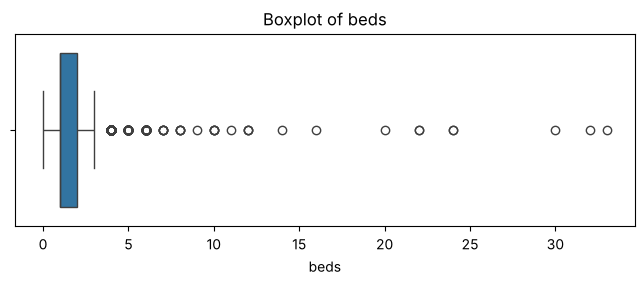

bathrooms
count    4699.000000
mean        1.235050
std         0.559305
min         0.000000
25%         1.000000
50%         1.000000
75%         1.500000
max        17.000000
Name: bathrooms, dtype: float64


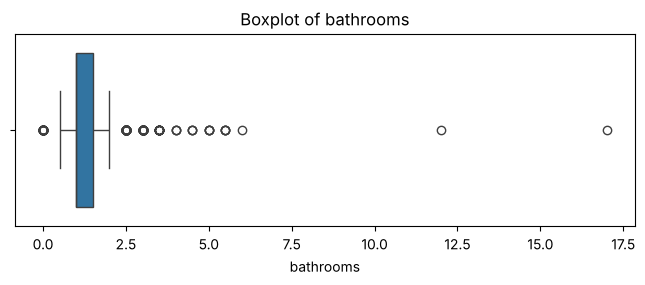

bedrooms
count    4692.000000
mean        1.495737
std         0.893248
min         0.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: bedrooms, dtype: float64


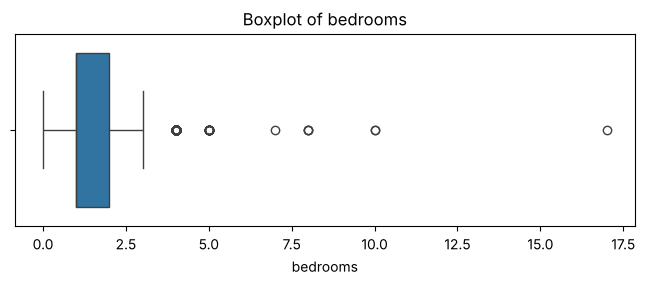

reviews_per_month
count    4162.000000
mean        1.363635
std         2.616099
min         0.010000
25%         0.300000
50%         0.595000
75%         1.600000
max        99.420000
Name: reviews_per_month, dtype: float64


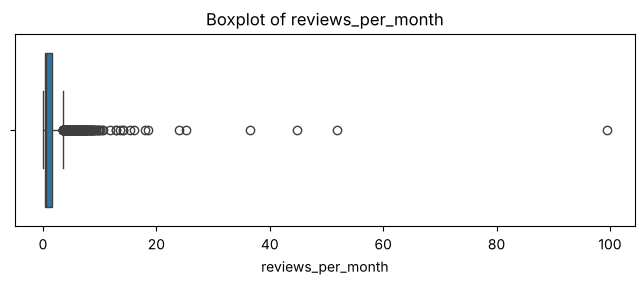

review_scores_rating
count    4162.000000
mean        4.836720
std         0.259677
min         1.000000
25%         4.780000
50%         4.910000
75%         5.000000
max         5.000000
Name: review_scores_rating, dtype: float64


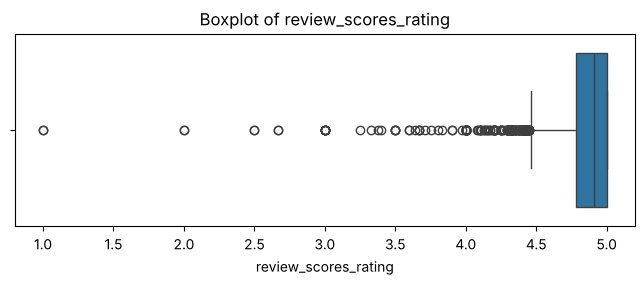

review_scores_cleanliness
count    4162.000000
mean        4.781173
std         0.310425
min         1.000000
25%         4.700000
50%         4.870000
75%         5.000000
max         5.000000
Name: review_scores_cleanliness, dtype: float64


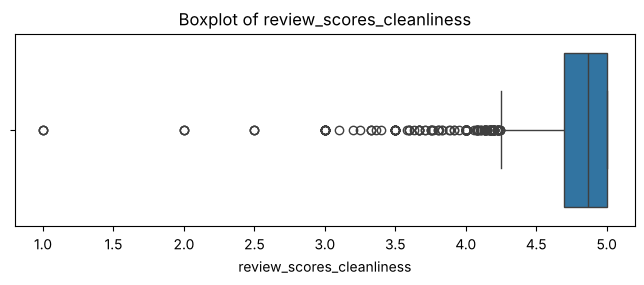

review_scores_accuracy
count    4162.000000
mean        4.843791
std         0.256294
min         1.000000
25%         4.800000
50%         4.910000
75%         5.000000
max         5.000000
Name: review_scores_accuracy, dtype: float64


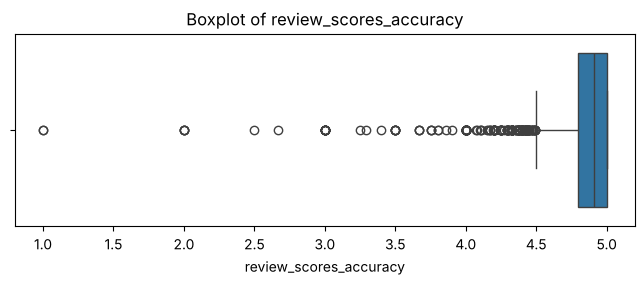

review_scores_communication
count    4162.000000
mean        4.902511
std         0.215529
min         1.000000
25%         4.890000
50%         4.980000
75%         5.000000
max         5.000000
Name: review_scores_communication, dtype: float64


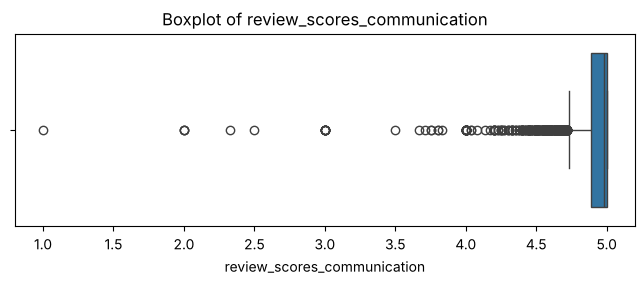

review_scores_location
count    4162.000000
mean        4.822977
std         0.224853
min         2.000000
25%         4.740000
50%         4.890000
75%         5.000000
max         5.000000
Name: review_scores_location, dtype: float64


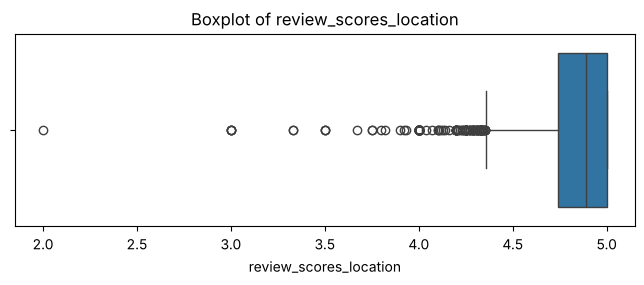

review_scores_value
count    4162.000000
mean        4.647374
std         0.315148
min         1.000000
25%         4.520000
50%         4.690000
75%         4.830000
max         5.000000
Name: review_scores_value, dtype: float64


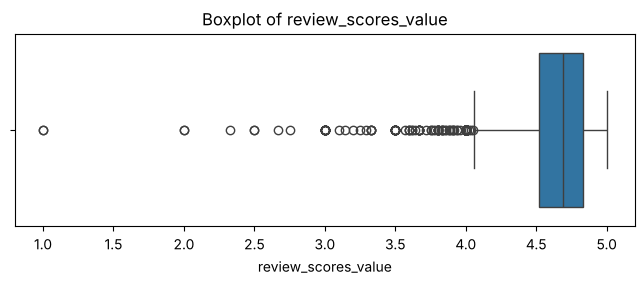

review_scores_checkin
count    4162.000000
mean        4.892328
std         0.207855
min         1.000000
25%         4.870000
50%         4.960000
75%         5.000000
max         5.000000
Name: review_scores_checkin, dtype: float64


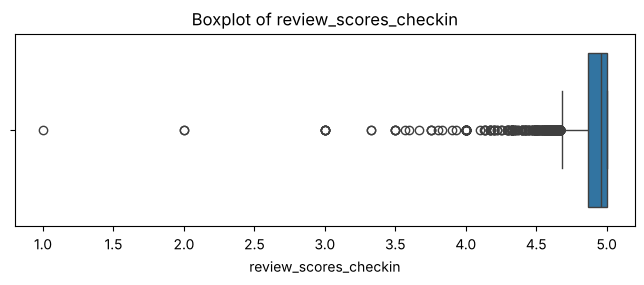

minimum_minimum_nights
count    4695.000000
mean        3.375080
std         9.817492
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max       300.000000
Name: minimum_minimum_nights, dtype: float64


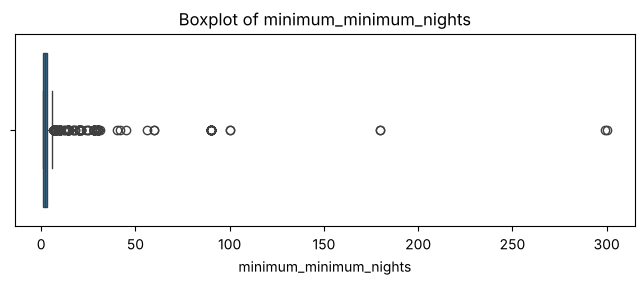

minimum_maximum_nights
count    4695.000000
mean      364.417039
std       433.895917
min         1.000000
25%        22.000000
50%        93.000000
75%       365.000000
max      1125.000000
Name: minimum_maximum_nights, dtype: float64


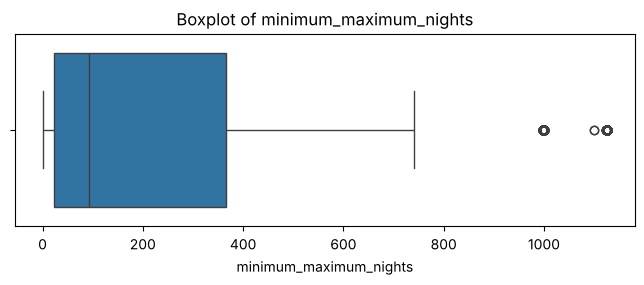

maximum_minimum_nights
count    4695.000000
mean        4.884132
std        14.886239
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max       529.000000
Name: maximum_minimum_nights, dtype: float64


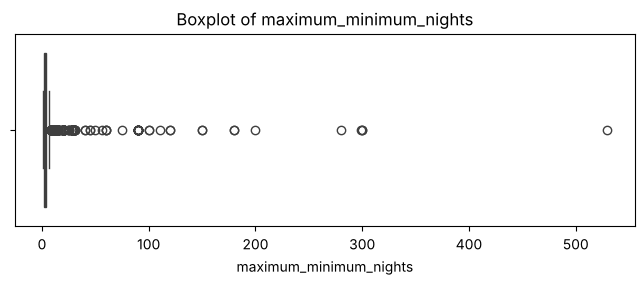

maximum_maximum_nights
count    4695.000000
mean      389.602769
std       443.265559
min         1.000000
25%        27.000000
50%       360.000000
75%       730.000000
max      1125.000000
Name: maximum_maximum_nights, dtype: float64


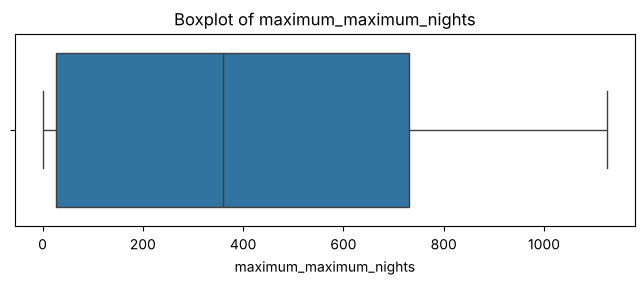

host_total_listings_count
count    4697.000000
mean        6.685757
std        69.359761
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max      1655.000000
Name: host_total_listings_count, dtype: float64


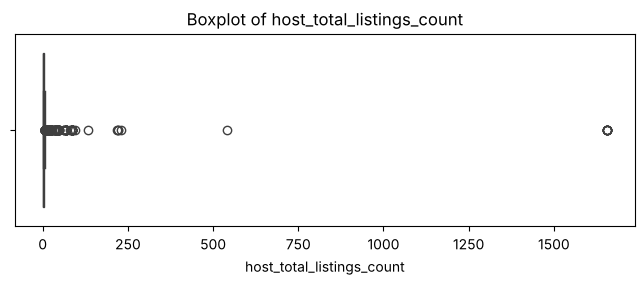

host_listings_count
count    4697.000000
mean        3.687460
std        24.981796
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       569.000000
Name: host_listings_count, dtype: float64


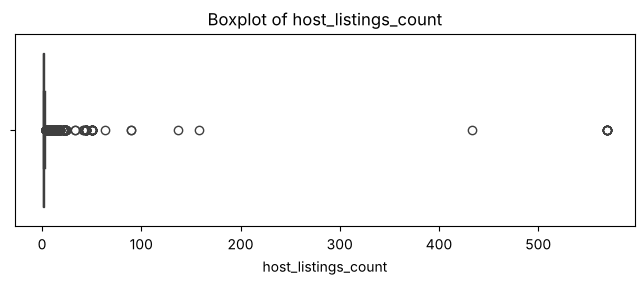

In [21]:
numeric_columns = [

    # Property
    # Some features can be safely imputed using the mean or median
    "beds",
    "bathrooms",
    "bedrooms",

    # Reviews
    # Review and rating features will be imputed using either the mean or median,
    # depending on the impact of outliers on the feature's distribution.
    # Additionally, a new binary indicator column will be created to mark records
    # where the original value was missing before imputation.
    "reviews_per_month",
    "review_scores_rating",
    "review_scores_cleanliness",
    "review_scores_accuracy",
    "review_scores_communication",
    "review_scores_location",
    "review_scores_value",
    "review_scores_checkin",

    # Nights
    # Some features can be safely imputed using the mean or median
    "minimum_minimum_nights",
    "minimum_maximum_nights",
    "maximum_minimum_nights",
    "maximum_maximum_nights",

    # Host
    # Some features can be safely imputed using the mean or median
    "host_total_listings_count",
    "host_listings_count"
]

import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
for column in numeric_columns:

    print("=" * 80)
    print(f"{column}")
    print("=" * 80)

    print(df_train[column].describe())

    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=df_train[column])

    plt.title(f"Boxplot of {column}")

    plt.show()

After analyzing all numerical features, we identified the columns where the mean is more affected by outliers. Therefore, missing values in these features will be imputed using the median.

In [22]:
Numerical_columns = [

    # Property
    "beds",
    "bathrooms",
    "bedrooms",

    # Reviews
    "reviews_per_month",
    "review_scores_rating",
    "review_scores_cleanliness",
    "review_scores_accuracy",
    "review_scores_communication",
    "review_scores_location",
    "review_scores_value",
    "review_scores_checkin",

    # Nights
    "minimum_minimum_nights",
    "minimum_maximum_nights",
    "maximum_minimum_nights",
    "maximum_maximum_nights",

    # Host
    "host_total_listings_count",
    "host_listings_count"

]

Apply median imputation only to the training data.

Add missing-value indicators before median imputation to preserve the information carried by missingness.




One column stores the imputed value, while the second indicates whether the original value was missing.

In [23]:
for column in Numerical_columns:

    df_train[f"{column}_missing"] = (
        df_train[column].isna().astype(int)
    )

    df_test[f"{column}_missing"] = (
        df_test[column].isna().astype(int)
    )

    median_value = df_train[column].median()

    df_train[column] = df_train[column].fillna(median_value)

    df_test[column] = df_test[column].fillna(median_value)

In [24]:
df_train[Numerical_columns].isnull().sum()

beds                           0
bathrooms                      0
bedrooms                       0
reviews_per_month              0
review_scores_rating           0
review_scores_cleanliness      0
review_scores_accuracy         0
review_scores_communication    0
review_scores_location         0
review_scores_value            0
review_scores_checkin          0
minimum_minimum_nights         0
minimum_maximum_nights         0
maximum_minimum_nights         0
maximum_maximum_nights         0
host_total_listings_count      0
host_listings_count            0
dtype: int64

In [25]:
numeric_missing = (
    df_train
    .select_dtypes(include=["int64", "float64"])
    .isnull()
    .sum()
)

numeric_missing[numeric_missing > 0]

Series([], dtype: int64)

# Case Four

## Percentage-based features: `host_response_rate`

The values are stored as text with a trailing "%" sign, which is removed before conversion to numbers.

In [26]:
df_train["host_response_rate"].sample(20, random_state=42)

9929      88%
130       91%
6034     100%
9793      88%
2150     100%
2827     100%
5288     100%
10250     NaN
2834      NaN
2448     100%
10254    100%
7662      94%
608      100%
7283     100%
9051      NaN
3972     100%
9891     100%
9855      67%
6917     100%
597      100%
Name: host_response_rate, dtype: str

# Cleaning 
removed %

In [27]:
df_train["host_response_rate"] = df_train["host_response_rate"].str.replace("%", "", regex=False)
df_test["host_response_rate"] = df_test["host_response_rate"].str.replace("%", "", regex=False)

# Data Type 
Str ----> Int

In [28]:
df_train["host_response_rate"] = pd.to_numeric(df_train["host_response_rate"])
df_test["host_response_rate"] = pd.to_numeric(df_test["host_response_rate"])

Now, we will handle the missing values in this feature.

count    4012.000000
mean       90.881107
std        22.184682
min         0.000000
25%        97.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: host_response_rate, dtype: float64


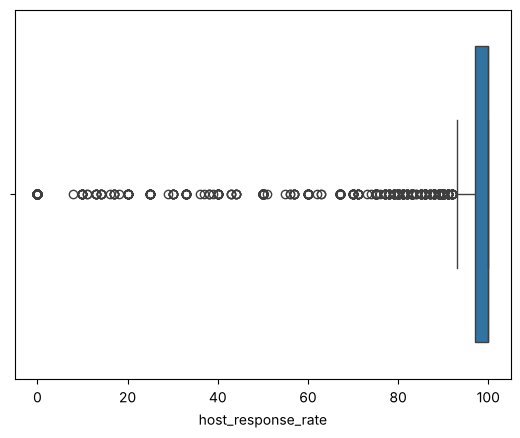

In [29]:
print(df_train["host_response_rate"].describe())

sns.boxplot(x=df_train["host_response_rate"])
plt.show()

In [30]:
median_response_rate = df_train["host_response_rate"].median()

df_train["host_response_rate"] = df_train["host_response_rate"].fillna(median_response_rate)
df_test["host_response_rate"] = df_test["host_response_rate"].fillna(median_response_rate)

## `host_acceptance_rate`

In [31]:
df_train["host_acceptance_rate"].head(20)

7225      46%
8788      94%
6831      88%
9815     100%
6940       0%
8652      40%
7925     100%
10378    100%
9559     100%
5675      69%
349      100%
8513      30%
8613      20%
5395      98%
125       98%
4758     100%
7353       0%
9867      77%
7464      NaN
10431    100%
Name: host_acceptance_rate, dtype: str

In [32]:
df_train["host_acceptance_rate"] = df_train["host_acceptance_rate"].str.replace("%", "", regex=False)
df_test["host_acceptance_rate"] = df_test["host_acceptance_rate"].str.replace("%", "", regex=False)

In [33]:
df_train["host_acceptance_rate"] = pd.to_numeric(df_train["host_acceptance_rate"])
df_test["host_acceptance_rate"] = pd.to_numeric(df_test["host_acceptance_rate"])

In [34]:
df_train["host_acceptance_rate"].describe()

count    4380.000000
mean       69.841324
std        32.694237
min         0.000000
25%        48.000000
50%        80.000000
75%       100.000000
max       100.000000
Name: host_acceptance_rate, dtype: float64

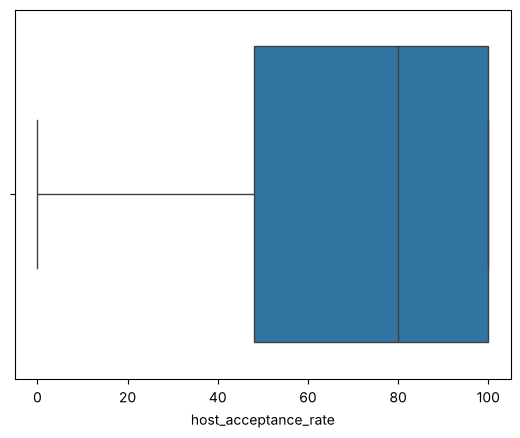

In [35]:
sns.boxplot(
    x=df_train["host_acceptance_rate"]
)

plt.show()

In [36]:
median_acceptance_rate = df_train["host_acceptance_rate"].median()

df_train["host_acceptance_rate"] = df_train["host_acceptance_rate"].fillna(median_acceptance_rate)
df_test["host_acceptance_rate"] = df_test["host_acceptance_rate"].fillna(median_acceptance_rate)

# Case Five

This column contains a mix of numeric values and text

In [37]:
df_train["bathrooms_text"].value_counts().head(20)

bathrooms_text
1 bath               2416
1.5 baths             936
1 private bath        517
2 baths               268
1 shared bath         216
1.5 shared baths       90
2.5 baths              84
3 baths                58
0 baths                29
Half-bath              16
3.5 baths              16
0 shared baths         15
Shared half-bath        6
5 baths                 4
2 shared baths          4
5.5 baths               4
4.5 baths               3
3 shared baths          3
Private half-bath       3
4 baths                 3
Name: count, dtype: int64

# Feature Engineering

In [38]:
import re

In [39]:
df_train["bathrooms_number"] = df_train["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0].astype(float)
df_test["bathrooms_number"] = df_test["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0].astype(float)

Replace entries that do not start with a numeric value with NaN.

In [40]:
df_train.loc[df_train["bathrooms_text"].str.contains("Half-bath", case=False, na=False), "bathrooms_number"] = 0.5
df_test.loc[df_test["bathrooms_text"].str.contains("Half-bath", case=False, na=False), "bathrooms_number"] = 0.5

In [41]:
df_train[
    [
        "bathrooms_text",
        "bathrooms_number"
    ]
].sample(20, random_state=42)

,bathrooms_text,bathrooms_number
9929,1.5 baths,1.5
130,1 bath,1.0
6034,1.5 baths,1.5
9793,1 bath,1.0
2150,1.5 baths,1.5
2827,1.5 baths,1.5
5288,1 bath,1.0
10250,1 shared bath,1.0
2834,1.5 baths,1.5
2448,1.5 baths,1.5


In [42]:
df_train = df_train.drop(columns=["bathrooms_text"])
df_test = df_test.drop(columns=["bathrooms_text"])

In [43]:
df_train["bathrooms_number"].isnull().sum()

np.int64(5)

In [44]:
median_bathrooms = df_train["bathrooms_number"].median()

df_train["bathrooms_number"] = df_train["bathrooms_number"].fillna(median_bathrooms)
df_test["bathrooms_number"] = df_test["bathrooms_number"].fillna(median_bathrooms)

Note: We generally prefer the median for missing-value imputation because it is less sensitive to outliers than the mean.

# Case Six

## `host_since`

This feature represents a since, which may have limited value for the model. However, it can be used in feature engineering to extract useful information, such as the host’s experience duration.

In [45]:
df_train["host_since"].head(20)

7225     2016-05-12
8788     2014-10-14
6831     2022-10-21
9815     2013-05-22
6940     2017-07-08
8652     2016-10-08
7925     2024-01-30
10378    2016-11-03
9559     2020-08-25
5675     2014-08-18
349      2013-10-14
8513     2021-04-01
8613     2012-08-23
5395     2017-02-13
125      2012-10-07
4758     2022-03-25
7353     2023-11-25
9867     2022-07-12
7464     2023-12-19
10431    2020-09-03
Name: host_since, dtype: str

In [46]:
df_train["host_since"].dtype

<StringDtype(na_value=nan)>

In [47]:
df_train["host_since"] = pd.to_datetime(df_train["host_since"])
df_test["host_since"] = pd.to_datetime(df_test["host_since"])

In [48]:
df_train["host_since"].dtype

dtype('<M8[us]')

# Feature Engineering

In [49]:
# Inside Airbnb scrape date for this snapshot (see `last_scraped` in the raw data)
reference_date = pd.Timestamp("2025-09-11")

df_train["host_experience_years"] = (reference_date - df_train["host_since"]).dt.days / 365
df_test["host_experience_years"] = (reference_date - df_test["host_since"]).dt.days / 365

In [50]:
df_train = df_train.drop(columns=["host_since"])
df_test = df_test.drop(columns=["host_since"])

In [51]:
df_train["host_experience_years"].head(20)

7225      9.339726
8788     10.917808
6831      2.893151
9815     12.315068
6940      8.183562
8652      8.931507
7925      1.616438
10378     8.860274
9559      5.049315
5675     11.073973
349      11.917808
8513      4.449315
8613     13.060274
5395      8.580822
125      12.936986
4758      3.468493
7353      1.797260
9867      3.169863
7464      1.731507
10431     5.024658
Name: host_experience_years, dtype: float64

In [52]:
df_train["host_experience_years"].describe()

count    4697.000000
mean        8.934812
std         3.489084
min         0.035616
25%         6.904110
50%         9.731507
75%        11.452055
max        16.926027
Name: host_experience_years, dtype: float64

In [53]:
median_experience = df_train["host_experience_years"].median()

df_train["host_experience_years"] = df_train["host_experience_years"].fillna(median_experience)
df_test["host_experience_years"] = df_test["host_experience_years"].fillna(median_experience)

## `first_review`

In [54]:
df_train["first_review"].value_counts(dropna=False).head(20)

first_review
NaN           537
2025-05-04     18
2025-04-13     18
2025-04-21     18
2025-01-02     16
2024-09-15     15
2024-07-07     15
2024-09-29     14
2024-10-20     14
2023-08-27     14
2024-01-02     13
2024-01-01     13
2024-09-16     12
2024-12-30     12
2023-10-15     12
2025-06-01     12
2024-04-21     11
2025-01-01     11
2022-09-11     11
2025-04-14     11
Name: count, dtype: int64

In [55]:
df_train["first_review"].isnull().sum()

np.int64(537)

In [56]:
df_train["first_review"] = pd.to_datetime(df_train["first_review"])
df_test["first_review"] = pd.to_datetime(df_test["first_review"])

In [57]:
df_train["first_review"].dtype

dtype('<M8[us]')

## `last_review`

In [58]:
df_train["last_review"].value_counts(dropna=False).head(20)

last_review
NaN           537
2025-09-07    158
2025-09-01    125
2025-08-24    117
2025-08-31    117
2025-08-25     94
2025-09-08     83
2025-08-17     76
2025-09-06     69
2025-08-27     67
2025-08-26     60
2025-09-05     59
2025-08-23     57
2025-08-10     54
2025-09-09     50
2025-08-22     47
2025-08-03     47
2025-08-18     46
2025-09-02     43
2025-09-10     43
Name: count, dtype: int64

In [59]:
df_train["last_review"].isnull().sum()

np.int64(537)

In [60]:
df_train["last_review"] = pd.to_datetime(df_train["last_review"])
df_test["last_review"] = pd.to_datetime(df_test["last_review"])

In [61]:
df_train["last_review"].dtype

dtype('<M8[us]')

#  Feature Engineering 2 + 3 Feature
We will use feature engineering to combine information from two columns and create a single, more useful feature for the model.

In [62]:
df_train["review_period_days"] = (df_train["last_review"] - df_train["first_review"]).dt.days
df_test["review_period_days"] = (df_test["last_review"] - df_test["first_review"]).dt.days

In [63]:
df_train["review_period_days"] = df_train["review_period_days"].fillna(0)
df_test["review_period_days"] = df_test["review_period_days"].fillna(0)

In [64]:
df_train[
    ["first_review", "last_review", "review_period_days"]
].head(20)


,first_review,last_review,review_period_days
7225,2023-11-05,2024-09-15,315.0
8788,2024-09-15,2025-09-06,356.0
6831,2024-08-04,2024-09-24,51.0
9815,NaT,NaT,0.0
6940,2024-09-16,2024-09-16,0.0
8652,2024-09-02,2025-06-09,280.0
7925,2024-05-17,2025-09-04,475.0
10378,NaT,NaT,0.0
9559,NaT,NaT,0.0
5675,2022-12-30,2025-05-31,883.0


In [65]:
df_train = df_train.drop(columns=["first_review", "last_review"])
df_test = df_test.drop(columns=["first_review", "last_review"])

# Start by handling categorical and text-based features, including columns with missing values.

# Categorical (Low-cardinality categorical feature)

# Case One

This features contains a limited number of predefined categories, making it suitable for one-hot encoding without creating excessive new features.

In [66]:
df_train["host_response_time"].value_counts(dropna=False)

host_response_time
within an hour        1972
within a few hours     960
within a day           837
NaN                    687
a few days or more     243
Name: count, dtype: int64

In [67]:
df_train["host_response_time"] = df_train["host_response_time"].fillna("Unknown")
df_test["host_response_time"] = df_test["host_response_time"].fillna("Unknown")

In [68]:
df_train["host_response_time"].value_counts()

host_response_time
within an hour        1972
within a few hours     960
within a day           837
Unknown                687
a few days or more     243
Name: count, dtype: int64

In [69]:
df_train["host_is_superhost"].value_counts(dropna=False)

host_is_superhost
f      3436
t      1215
NaN      48
Name: count, dtype: int64

In [70]:
df_train["host_is_superhost"] = (
    df_train["host_is_superhost"]
    .fillna("Unknown")
)

df_test["host_is_superhost"] = (
    df_test["host_is_superhost"]
    .fillna("Unknown")
)

In [71]:
df_train ["host_is_superhost"].value_counts()

host_is_superhost
f          3436
t          1215
Unknown      48
Name: count, dtype: int64

In [72]:
df_train["host_identity_verified"].value_counts(dropna=False)

host_identity_verified
t      4523
f       174
NaN       2
Name: count, dtype: int64

In [73]:
df_train["host_identity_verified"] = (
    df_train["host_identity_verified"]
    .fillna("Unknown")
)

df_test["host_identity_verified"] = (
    df_test["host_identity_verified"]
    .fillna("Unknown")
)

In [74]:
df_train["host_identity_verified"].value_counts()

host_identity_verified
t          4523
f           174
Unknown       2
Name: count, dtype: int64

In [75]:
df_train["host_has_profile_pic"].value_counts(dropna=False)

host_has_profile_pic
t      4633
f        64
NaN       2
Name: count, dtype: int64

In [76]:
df_train["host_has_profile_pic"] = (
    df_train["host_has_profile_pic"]
    .fillna("Unknown")
)

df_test["host_has_profile_pic"] = (
    df_test["host_has_profile_pic"]
    .fillna("Unknown")
)

In [77]:
df_train["host_has_profile_pic"].value_counts()

host_has_profile_pic
t          4633
f            64
Unknown       2
Name: count, dtype: int64

In [78]:
df_train["has_availability"].value_counts(dropna=False)

has_availability
t      4590
NaN     109
Name: count, dtype: int64

In [79]:
df_train["has_availability"] = df_train["has_availability"].fillna("Unknown")
df_test["has_availability"] = df_test["has_availability"].fillna("Unknown")

In [80]:
df_train["has_availability"].value_counts(dropna=False)

has_availability
t          4590
Unknown     109
Name: count, dtype: int64

# High-cardinality categorical feature

This is a high-cardinality categorical feature with many unique categories, which may create a large number of features after one-hot encoding.

## `host_location`

In [81]:
df_train["host_location"].value_counts(dropna=False).head(20)

host_location
Amsterdam, Netherlands     3830
NaN                         544
Netherlands                 156
London, United Kingdom        9
The Hague, Netherlands        6
Utrecht, Netherlands          6
Rotterdam, Netherlands        5
Huizen, Netherlands           4
Brussels, Belgium             4
Groningen, Netherlands        4
Arnhem, Netherlands           3
Paris, France                 3
Haarlem, Netherlands          3
Zunderdorp, Netherlands       3
Los Angeles, CA               3
Breda, Netherlands            3
Bergen, Netherlands           3
Amstelveen, Netherlands       3
Barcelona, Spain              3
Zandvoort, Netherlands        2
Name: count, dtype: int64

In [82]:
df_train["host_location"].nunique(dropna=True)

107

In [83]:
df_train["host_location"].nunique(dropna=False)

108

# Feature Engineering

“host_location” contains many categorical values, so one-hot encoding it could create approximately 125 new features.

Feature engineering simplifies samples containing multiple categories by extracting a single, meaningful category for the model.

In [84]:
df_train["host_country"] = df_train["host_location"].str.split(", ").str[-1]
df_test["host_country"] = df_test["host_location"].str.split(", ").str[-1]

Missing values are replaced with “Unknown” so the model can recognize them as missing or undefined information.

In [85]:
df_train["host_country"] = df_train["host_country"].fillna("Unknown")
df_test["host_country"] = df_test["host_country"].fillna("Unknown")

In [86]:
df_train["host_country"].value_counts()

host_country
Netherlands       4081
Unknown            544
United Kingdom      11
CA                   6
Spain                6
Germany              5
France               5
Belgium              5
Egypt                4
South Africa         3
Australia            3
NY                   2
Italy                2
Costa Rica           2
United States        2
Japan                1
Georgia              1
Ireland              1
New Caledonia        1
Colombia             1
Ukraine              1
Guernsey             1
Brazil               1
Greece               1
Uganda               1
Monaco               1
Portugal             1
Argentina            1
Croatia              1
Switzerland          1
Mexico               1
Denmark              1
India                1
Name: count, dtype: int64

# Cleaning
Different formats and abbreviations can confuse the model, so all country names and abbreviations should be standardized to a consistent format.

In [87]:
df_train.loc[
    df_train["host_country"].isin(["CA", "NY", "WA"]),
    "host_location"
].value_counts()

host_location
Los Angeles, CA      3
New York, NY         2
San Francisco, CA    2
Berkeley, CA         1
Name: count, dtype: int64

We standardized the country/state abbreviations that were identified as inconsistent and rechecked the data afterward.

In [88]:
us_locations = [
    "New York, NY", "Los Angeles, CA", "San Francisco, CA",
    "Berkeley, CA", "Bothell, WA"
]

df_train.loc[df_train["host_location"].isin(us_locations), "host_country"] = "United States"
df_test.loc[df_test["host_location"].isin(us_locations), "host_country"] = "United States"

In [89]:
df_train = df_train.drop(columns=["host_location"])
df_test = df_test.drop(columns=["host_location"])

If no additional abbreviations are found, the data is considered standardized for this issue

In [90]:
df_train["host_country"].value_counts()

host_country
Netherlands       4081
Unknown            544
United Kingdom      11
United States       10
Spain                6
Germany              5
France               5
Belgium              5
Egypt                4
South Africa         3
Australia            3
Italy                2
Costa Rica           2
Japan                1
Georgia              1
Ireland              1
New Caledonia        1
Colombia             1
Ukraine              1
Guernsey             1
Brazil               1
Greece               1
Uganda               1
Monaco               1
Portugal             1
Argentina            1
Croatia              1
Switzerland          1
Mexico               1
Denmark              1
India                1
Name: count, dtype: int64

# Rare categories

 reduce the number of features generated during one-hot encoding by grouping infrequent categories into “Others”.

A frequency threshold is applied: categories appearing 5 or more times are kept, while less frequent categories are grouped into “Others”.

In [91]:
country_counts = df_train["host_country"].value_counts()

rare_countries = country_counts[country_counts < 5].index
known_countries = country_counts[country_counts >= 5].index

df_train.loc[df_train["host_country"].isin(rare_countries), "host_country"] = "Other"

df_test.loc[df_test["host_country"].isin(rare_countries), "host_country"] = "Other"
df_test.loc[~df_test["host_country"].isin(known_countries) & (df_test["host_country"] != "Other"), "host_country"] = "Other"

In [92]:
df_train["host_country"].value_counts()

host_country
Netherlands       4081
Unknown            544
Other               32
United Kingdom      11
United States       10
Spain                6
Germany              5
France               5
Belgium              5
Name: count, dtype: int64

# Case Two

Features with an extremely high number of missing values are dropped directly, without missing-value imputation, cleaning, or feature simplification.

In [93]:
df_train["host_neighbourhood"].value_counts(dropna=False).head(20)

host_neighbourhood
NaN                                3561
Oud-West                            187
Grachtengordel                      118
Jordaan                              82
De Pijp                              64
Oosterparkbuurt                      45
Indische Buurt                       41
Nieuwmarkt en Lastage                40
Bos en Lommer                        35
Oost                                 34
De Wallen                            33
Hoofddorppleinbuurt                  33
Westelijke Eilanden                  29
Amsterdam Centrum                    28
Weesperbuurt en Plantage             24
Spaarndammer en Zeeheldenbuurt       23
Oostelijke Eilanden en Kadijken      22
Stadionbuurt                         20
Oud-Zuid                             20
Museumkwartier                       19
Name: count, dtype: int64

In [94]:
df_train = df_train.drop(columns=["host_neighbourhood"])
df_test = df_test.drop(columns=["host_neighbourhood"])

In [95]:
"host_neighbourhood" in df_train.columns

False

In [96]:
df_train["neighbourhood"].value_counts(dropna=False).head(20)

neighbourhood
NaN                                               2493
Amsterdam, Noord-Holland, Netherlands             1809
Amsterdam, North Holland, Netherlands              248
Amsterdam, NH, Netherlands                          73
Amsterdam, Netherlands                              24
Amsterdam, Nord Holland, Netherlands                10
Amsterdam-Zuidoost, North Holland, Netherlands       8
Amsterdam, Noord Holland, Netherlands                7
Amsterdam-Zuidoost, Noord-Holland, Netherlands       5
Watergraafsmeer, North Holland, Netherlands          2
Amsterdam, Haarlemmerbuurt, Netherlands              2
Amsterdam, Holland, Netherlands                      2
Badhoevedorp, Noord-Holland, Netherlands             1
Amsterdam, GD, Netherlands                           1
Lijnden, Noord-Holland, Netherlands                  1
Amsterdam, Emmy andriessestraat, Netherlands         1
Amsterdam, Overtoom, Netherlands                     1
Amsterdam , Noord-Holland, Netherlands             

In [97]:
df_train = df_train.drop(columns=["neighbourhood"])
df_test = df_test.drop(columns=["neighbourhood"])

In [98]:
"neighbourhood" in df_train.columns

False

If a feature contains information that is not useful for the model, such as the “name” column in this dataset, it will be dropped directly.

In [99]:
df_train["host_name"].value_counts(dropna=False).head(20)

host_name
Stephan      35
Mike         29
Laura        27
David        26
Thomas       26
Arnold       22
Suzanne      19
Anna         19
Luke         18
Nina         18
Joost        18
Anne         17
Michiel      17
Aimee        17
Jasper       16
Tim          16
Iris         16
Charlotte    16
Eva          15
Bart         15
Name: count, dtype: int64

In [100]:
df_train = df_train.drop(columns=["host_name"])
df_test = df_test.drop(columns=["host_name"])

In [101]:
"host_name" in df_train.columns

False

# Case Three

This feature contains multiple meaningful categories that can provide useful information to the model.

We can use feature engineering to extract separate features from these categories and replace the original column.

In [102]:
df_train["host_verifications"].value_counts(dropna=False).head(20)

host_verifications
['email', 'phone']                  3760
['email', 'phone', 'work_email']     480
['phone']                            431
['phone', 'work_email']               22
NaN                                    2
[]                                     2
['email']                              1
['email', 'work_email']                1
Name: count, dtype: int64

In [103]:
import ast

df_train["host_verifications"] = df_train["host_verifications"].fillna("[]").apply(ast.literal_eval)
df_test["host_verifications"] = df_test["host_verifications"].fillna("[]").apply(ast.literal_eval)

Feature engineering extracts meaningful 0/1 features, replacing missing values with 0 to indicate absence and reduce the missing-value problem.

In [104]:
for split_df in [df_train, df_test]:
    split_df["has_email_verification"] = split_df["host_verifications"].apply(lambda x: int("email" in x))
    split_df["has_phone_verification"] = split_df["host_verifications"].apply(lambda x: int("phone" in x))
    split_df["has_work_email_verification"] = split_df["host_verifications"].apply(lambda x: int("work_email" in x))

In [105]:
df_train[
    [
        "host_verifications",
        "has_email_verification",
        "has_phone_verification",
        "has_work_email_verification"
    ]
].head(20)

,host_verifications,has_email_verification,has_phone_verification,has_work_email_verification
7225,"[email, phone]",1,1,0
8788,"[email, phone]",1,1,0
6831,"[email, phone]",1,1,0
9815,"[email, phone]",1,1,0
6940,"[email, phone]",1,1,0
8652,"[email, phone]",1,1,0
7925,"[email, phone]",1,1,0
10378,[phone],0,1,0
9559,"[email, phone]",1,1,0
5675,"[email, phone]",1,1,0


In [106]:
df_train = df_train.drop(columns=["host_verifications"])
df_test = df_test.drop(columns=["host_verifications"])

In [107]:
"host_verifications" in df_train.columns

False

# Case Four: URL features

URL-based features are generally not useful for ML models and are usually dropped, unless they provide meaningful information in specific cases.

## `host_picture_url`

In [108]:
df_train["host_picture_url"].value_counts(dropna=False).head(10)

host_picture_url
https://a0.muscache.com/defaults/user_pic-225x225.png?v=3                                                                       64
https://a0.muscache.com/im/pictures/user/c5ac4264-f93b-4430-bdf8-bee75610b032.jpg?aki_policy=profile_x_medium                   22
https://a0.muscache.com/im/pictures/user/User/original/04d12c05-5a27-4a94-8f18-069e80d956e6.jpeg?aki_policy=profile_x_medium    21
https://a0.muscache.com/im/pictures/user/User/original/048d8039-0cfb-47ef-95d3-d3bd8597b760.jpeg?aki_policy=profile_x_medium    17
https://a0.muscache.com/im/pictures/user/4c2dbab6-3454-4d90-bf32-5a6d004d6593.jpg?aki_policy=profile_x_medium                   13
https://a0.muscache.com/im/pictures/user/1350e724-fc4e-4690-a93a-a595e5820fc8.jpg?aki_policy=profile_x_medium                   11
https://a0.muscache.com/im/pictures/user/fb79a2a5-ea38-4539-b7d1-9d0818f6670b.jpg?aki_policy=profile_x_medium                   10
https://a0.muscache.com/im/pictures/user/User/original/e3e5da86-08

The URL extension can provide useful information about whether the host uploaded a personal image or used a generic/external image, allowing us to create a meaningful feature from it.

In [109]:
for split_df in [df_train, df_test]:
    split_df["has_host_picture"] = (
        split_df["host_picture_url"].notna()
        & ~split_df["host_picture_url"].str.contains("default/user_pic", case=False, na=False)
    ).astype(int)

In [110]:
df_train = df_train.drop(columns=["host_picture_url"])
df_test = df_test.drop(columns=["host_picture_url"])

## Redundant feature

This feature repeats information already contained in the previous one and is dropped.

This feature contains redundant information already available in the previous feature, so it will be dropped to avoid duplication.

In [111]:
df_train["host_thumbnail_url"].value_counts(dropna=False).head(10)

host_thumbnail_url
https://a0.muscache.com/defaults/user_pic-50x50.png?v=3                                                                      64
https://a0.muscache.com/im/pictures/user/c5ac4264-f93b-4430-bdf8-bee75610b032.jpg?aki_policy=profile_small                   22
https://a0.muscache.com/im/pictures/user/User/original/04d12c05-5a27-4a94-8f18-069e80d956e6.jpeg?aki_policy=profile_small    21
https://a0.muscache.com/im/pictures/user/User/original/048d8039-0cfb-47ef-95d3-d3bd8597b760.jpeg?aki_policy=profile_small    17
https://a0.muscache.com/im/pictures/user/4c2dbab6-3454-4d90-bf32-5a6d004d6593.jpg?aki_policy=profile_small                   13
https://a0.muscache.com/im/pictures/user/1350e724-fc4e-4690-a93a-a595e5820fc8.jpg?aki_policy=profile_small                   11
https://a0.muscache.com/im/pictures/user/fb79a2a5-ea38-4539-b7d1-9d0818f6670b.jpg?aki_policy=profile_small                   10
https://a0.muscache.com/im/pictures/user/User/original/e3e5da86-086c-483c-b2a9-60bb42

In [112]:
df_train["host_thumbnail_url"].isnull().sum()

np.int64(2)

In [113]:
df_train = df_train.drop(columns=["host_thumbnail_url"])
df_test = df_test.drop(columns=["host_thumbnail_url"])

In [114]:
"host_thumbnail_url" in df_train.columns

False

# Case Five

License and document-related features contain unique codes for each sample, which can create a very high number of categories during one-hot encoding with little value for the model.


In [115]:
df_train["license"].value_counts(dropna=False).head(20)

license
Exempt                      400
NaN                          66
0363 78AD 8875 790E 3C05     13
ABCD1234AB1289EFA0F9          9
0363 033B 7FC4 5C3A DB9F      8
ABCD 1234 AB12 89EF A0F9      7
0363A27A90E5EDF39328          7
036341086EC3C2FF2493          4
0363 2A6D 7C09 877D 715F      4
0363 CE33 EA3C B22E 9328      4
0363 40B7 B08A C3C6 B53B      4
0363 9D14 8C36 267C 2B29      3
0363 CEB0 177A F1BD 666C      3
0363 ECFE 7345 29A0 BAC4      3
0363 2E44 7F4D 7C86 D485      3
0363033B7FC45C3ADB9f          3
0363 B6C0 C79B 8E40 932D      3
0363 A6C0 16C0 2606 7E49      3
0363 A753 EDE3 9B52 8929      3
0363 CCF2 9D8A 9B3E F830      3
Name: count, dtype: int64

In [116]:
df_train["license"].nunique()

3980

For now, missing values will be replaced with “Unknown” to represent missing information.

In [117]:
df_train["license"] = df_train["license"].fillna("Unknown")
df_test["license"] = df_test["license"].fillna("Unknown")

In [118]:
df_train["license"].isnull().sum()

np.int64(0)

In [119]:
df_train["license"].value_counts(dropna=False).head(20)

license
Exempt                      400
Unknown                      66
0363 78AD 8875 790E 3C05     13
ABCD1234AB1289EFA0F9          9
0363 033B 7FC4 5C3A DB9F      8
ABCD 1234 AB12 89EF A0F9      7
0363A27A90E5EDF39328          7
036341086EC3C2FF2493          4
0363 2A6D 7C09 877D 715F      4
0363 CE33 EA3C B22E 9328      4
0363 40B7 B08A C3C6 B53B      4
0363 9D14 8C36 267C 2B29      3
0363 CEB0 177A F1BD 666C      3
0363 ECFE 7345 29A0 BAC4      3
0363 2E44 7F4D 7C86 D485      3
0363033B7FC45C3ADB9f          3
0363 B6C0 C79B 8E40 932D      3
0363 A6C0 16C0 2606 7E49      3
0363 A753 EDE3 9B52 8929      3
0363 CCF2 9D8A 9B3E F830      3
Name: count, dtype: int64

We can use feature engineering to extract a simpler feature indicating whether the host is Licensed, Exempt, or Unknown.

In [120]:
import numpy as np

for split_df in [df_train, df_test]:
    split_df["license_status"] = np.select(
        [split_df["license"].eq("Exempt"), split_df["license"].eq("Unknown")],
        ["Exempt", "Unknown"],
        default="Licensed"
    )

In [121]:
df_train["license_status"].value_counts(dropna=True)

license_status
Licensed    4233
Exempt       400
Unknown       66
Name: count, dtype: int64

In [122]:
df_train = df_train.drop(columns=["license"])
df_test = df_test.drop(columns=["license"])

# Free - Text 


Free-text columns contain large amounts of unstructured information and require specialized processing. NLP is the preferred approach, while feature engineering can be used to extract simpler features when needed.

In [123]:
df_train["description"].dropna().head(5)

7225          Discover this stylish apartment in De Baarsjes. Just 5 minutes by bike from the bustling city center. You will find excellent public transportation 100 meters away and have the luxury of two beautiful parks, the Erasmus Park and Rembrandt Park, around the corner. Moreover, you never have to look far for cozy restaurants, because they can be found around the corner. And despite the proximity to the city center, you can enjoy the tranquility of this charming neighborhood. A perfect location to live!
8788                                           Casa Delea Cantina (@CasaDelea) is a new super luxuriously furnished double room with its own bathroom en suite with a marble shower and toilet. The washbasin is made with an original old design closet as well as the desk. <br /><br />Casa Delea Cantina is located in the bustling De Pijp district, the Latin Quarter of Amsterdam, within walking distance of restaurants, cafes, shops and public transport. We love to give insider tips f

In [124]:
df_train["description"].isnull().sum()

np.int64(183)

In [125]:
df_train["neighborhood_overview"].dropna().head(5)

7225    The Baarsjes is one of the most exciting neighborhoods in Amsterdam, located in the west part of the city. The neighborhood has undergone a true renaissance in the last years, now a melting pot of cultures, giving the neighborhood a unique charm.<br /><br />The architecture in De Baarsjes ranges from beautiful mansions from the early 20th century to modern apartment complexes. This mix of old and new buildings gives the neighborhood an eclectic feel. The streets are lined with trees and historical facades, which contributes to the atmosphere.<br /><br />What makes De Baarsjes really special is the diversity. It is home to people from different backgrounds and nationalities, which has led to a rich culinary scene with restaurants serving dishes from the whole world. Local markets and shops offer a range of products and ingredients, making it a true paradise for foodies.<br /><br />For nature lovers there are the beautiful Erasmus and Rembrandt parks, ideal places for hiking, exe

In [126]:
df_train["neighborhood_overview"].isnull().sum()

np.int64(2493)

In [127]:
df_train["host_about"].dropna().head(10)

7225                                         Hello,\n\nWe are Max and Joram, a young couple who have been living in Amsterdam for quite some time. To us, it's the most beautiful city in Europe! Since 2023, we've been residing in our apartment in the De Baarsjes neighborhood. In our free time, we enjoy traveling, staying active through sports, and embarking on new adventures together. In our professional lives, we are passionate about working with data and exploring its endless possibilities.
8788                                        Hallo,\n\nIk ben Ferdau Delea (Fries/Italiaans) en trotse moeder van twee kinderen. Samen wonen wij in het prachtige Amsterdam. Als Industrial en Interior Designer heb ik vol enthousiasme onze  B&B’s CasaDelea vormgegeven.\nReizen is mijn grote liefde. Ik geniet ervan om de wereld te verkennen en nieuwe mensen te ontmoeten. Onze twee B&B’s, te vinden op socials onder @CasaDelea, bieden gasten de kans om het beste van Amsterdam te ervaren.\n\nFerdau
9815  

In [128]:
df_train["host_about"].isnull().sum()

np.int64(2208)

In [129]:
df_train["name"].dropna().head(10)

7225     Design luxe appartement for two person with garden
8788             Casa Delea Cantina - Luxe kamer in De Pijp
6831     Close to Rijksmuseum! Two Units with Full Kitchens
9815                                     Spacious city home
6940                         Family house with sunny garden
8652                           Prachtig 4 kamer appartement
7925                     Spot-on home base for Arena events
10378           Luxe design appartement in de Rivierenbuurt
9559      NEW - Sweet & cosy garden view apartment OLD/WEST
5675                        Cosy, central located apartment
Name: name, dtype: str

In [130]:
df_train["name"].isnull().sum()

np.int64(0)

# Missing Indicator

The missing-value indicator preserves the presence of missing data in a form the model can understand, while keeping the original missing text empty for NLP processing.

In [131]:
text_cols = ["description", "neighborhood_overview", "host_about"]

for col in text_cols:
    df_train[f"{col}_missing"] = df_train[col].isna().astype(int)
    df_train[col] = df_train[col].fillna("")

    df_test[f"{col}_missing"] = df_test[col].isna().astype(int)
    df_test[col] = df_test[col].fillna("")

note : The Name column was retained because it contains no missing values.

In [132]:
df_train[
    [
        "description_missing",
        "neighborhood_overview_missing",
        "host_about_missing"
    ]
].sum()

description_missing               183
neighborhood_overview_missing    2493
host_about_missing               2208
dtype: int64

# Text Cleaning

In [133]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)           # removed HTML
    text = re.sub(r"http\S+|www\S+", " ", text)    # removed links or URL
    text = re.sub(r"\s+", " ", text).strip()       # removed extra spaces
    return text

In [134]:
text_cols = ["description", "neighborhood_overview", "host_about", "name"]

for col in text_cols:
    df_train[col] = df_train[col].apply(clean_text)
    df_test[col] = df_test[col].apply(clean_text)

In [135]:
df_train[text_cols].head()

,description,neighborhood_overview,host_about,name
7225,"discover this stylish apartment in de baarsjes. just 5 minutes by bike from the bustling city center. you will find excellent public transportation 100 meters away and have the luxury of two beautiful parks, the erasmus park and rembrandt park, around the corner. moreover, you never have to look far for cozy restaurants, because they can be found around the corner. and despite the proximity to the city center, you can enjoy the tranquility of this charming neighborhood. a perfect location to live!","the baarsjes is one of the most exciting neighborhoods in amsterdam, located in the west part of the city. the neighborhood has undergone a true renaissance in the last years, now a melting pot of cultures, giving the neighborhood a unique charm. the architecture in de baarsjes ranges from beautiful mansions from the early 20th century to modern apartment complexes. this mix of old and new buildings gives the neighborhood an eclectic feel. the streets are lined with trees and historical facades, which contributes to the atmosphere. what makes de baarsjes really special is the diversity. it is home to people from different backgrounds and nationalities, which has led to a rich culinary scene with restaurants serving dishes from the whole world. local markets and shops offer a range of products and ingredients, making it a true paradise for foodies. for nature lovers there are the beautiful erasmus and rembrandt parks, ideal places for hiking, exercising","hello, we are max and joram, a young couple who have been living in amsterdam for quite some time. to us, it's the most beautiful city in europe! since 2023, we've been residing in our apartment in the de baarsjes neighborhood. in our free time, we enjoy traveling, staying active through sports, and embarking on new adventures together. in our professional lives, we are passionate about working with data and exploring its endless possibilities.",design luxe appartement for two person with garden
8788,"casa delea cantina (@casadelea) is a new super luxuriously furnished double room with its own bathroom en suite with a marble shower and toilet. the washbasin is made with an original old design closet as well as the desk. casa delea cantina is located in the bustling de pijp district, the latin quarter of amsterdam, within walking distance of restaurants, cafes, shops and public transport. we love to give insider tips for a unique amsterdam experience.",,"hallo, ik ben ferdau delea (fries/italiaans) en trotse moeder van twee kinderen. samen wonen wij in het prachtige amsterdam. als industrial en interior designer heb ik vol enthousiasme onze b&b’s casadelea vormgegeven. reizen is mijn grote liefde. ik geniet ervan om de wereld te verkennen en nieuwe mensen te ontmoeten. onze twee b&b’s, te vinden op socials onder @casadelea, bieden gasten de kans om het beste van amsterdam te ervaren. ferdau",casa delea cantina - luxe kamer in de pijp
6831,"enjoy a home-away-from-home experience in the heart of amsterdam, featuring spacious suites perfect for both short and long stays. each suite comes equipped with a fully stocked kitchen, complete with a dishwasher, allowing you to cook your own meals if you wish. additional amenities include a comfortable lounge area perfect for relaxation and a work desk for business needs. the property also offers bicycle rentals, offering a fun and eco-friendly way to explore the city.",- van gogh museum- 1.6 miles; - moco museum- 1.6 miles; - rijksmuseum- 1.7 miles; - leidseplein- 1.9 miles; - royal palace amsterdam- 2.7 miles; - dam square- 2.7 miles; - artis zoo- 2.8 miles; - beurs van berlage- 2.9 miles; - a'dam lookout- 3.5 miles; - schiphol airport- 5 miles,,close to rijksmuseum! two units with full kitchens
9815,"welcome to your perfect family getaway in amsterdam! this spacious, tastefully decorated home offers all the comfort and convenience you need for a memorable stay. with three generous bedr

We can also use scikit-learn to access a predefined list of stop words for text preprocessing.

In [136]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [137]:
stop_words = list(ENGLISH_STOP_WORDS)

Note : Instead of removing stop words directly, we define them in a list and pass this list to TF-IDF, allowing stop words to be filtered during text-to-numeric transformation.

# TF-IDF vectorization

Fit one TF-IDF vectorizer per text column on the training text only, then apply it to the test text.

In [138]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_matrices_train = {}
tfidf_matrices_test = {}
tfidf_vectorizers = {}

for col in text_cols:
    vectorizer = TfidfVectorizer(
        max_features=500,
        min_df=2,
        max_df=0.95,
        stop_words="english"
    )

    # Learn vocabulary + weights from TRAINING text only
    train_matrix = vectorizer.fit_transform(df_train[col])

    # Apply that same learned vocabulary to test text — no re-fitting
    test_matrix = vectorizer.transform(df_test[col])

    tfidf_vectorizers[col] = vectorizer
    tfidf_matrices_train[col] = train_matrix
    tfidf_matrices_test[col] = test_matrix

In [139]:
for col in text_cols:
    print(col, "→ train:", tfidf_matrices_train[col].shape, "| test:", tfidf_matrices_test[col].shape)

description → train: (4699, 500) | test: (1175, 500)
neighborhood_overview → train: (4699, 500) | test: (1175, 500)
host_about → train: (4699, 500) | test: (1175, 500)
name → train: (4699, 500) | test: (1175, 500)


Note: this produces one sparse matrix per text column.

Combine the per-column matrices into a single matrix with `hstack`.

In [140]:
from scipy.sparse import hstack

text_tfidf_train = hstack([
    tfidf_matrices_train["description"],
    tfidf_matrices_train["neighborhood_overview"],
    tfidf_matrices_train["host_about"],
    tfidf_matrices_train["name"]
])

text_tfidf_test = hstack([
    tfidf_matrices_test["description"],
    tfidf_matrices_test["neighborhood_overview"],
    tfidf_matrices_test["host_about"],
    tfidf_matrices_test["name"]
])

In [141]:
text_tfidf_train.shape

(4699, 2000)

In [142]:
text_cols = [
    "description",
    "neighborhood_overview",
    "host_about",
    "name"
]

In [143]:
df_train = df_train.drop(columns=text_cols)
df_test = df_test.drop(columns=text_cols)

In [144]:
df_train.shape

(4699, 87)

Merge the single feature matrix with the remaining dataset to create the final combined dataset.

In [145]:
tfidf_feature_names = []
for col in text_cols:
    features = tfidf_vectorizers[col].get_feature_names_out()
    tfidf_feature_names.extend([f"{col}_tfidf_{word}" for word in features])

# Dense float64 columns: absent terms are exactly 0.0 (no NaN), which also
# avoids sparse-extension dtypes that parquet cannot store reliably.
tfidf_df_train = pd.DataFrame(
    text_tfidf_train.toarray(), index=df_train.index, columns=tfidf_feature_names
)
tfidf_df_test = pd.DataFrame(
    text_tfidf_test.toarray(), index=df_test.index, columns=tfidf_feature_names
)

df_train = pd.concat([df_train, tfidf_df_train], axis=1)
df_test = pd.concat([df_test, tfidf_df_test], axis=1)
print("TF-IDF columns added:", len(tfidf_feature_names))


TF-IDF columns added: 2000


In [146]:
df_train.shape

(4699, 2087)

# Cleaning Non-Missing Features

The `amenities` column is a list-valued feature that contains a number of distinct categories.

In [147]:
df_train["amenities"].head(10)

7225                                                                                                                                                                                                                                                                                                                                                                                                                                                     ["Backyard", "Free dryer \u2013 In unit", "Wifi", "Washer", "Cleaning products", "TV", "Hot water", "Central heating", "Cooking basics", "Dishes and silverware", "Coffee maker", "Fire extinguisher", "Outdoor dining area", "Garden view", "Paid parking on premises", "Carbon monoxide alarm", "Smoke alarm", "Refrigerator", "Kitchen", "Exterior security cameras on property"]
8788                                                                                                                                                                               ["Coffe

In [148]:
df_train["amenities"].isnull().sum()

np.int64(0)

First, use a loop to identify all the different types of amenities available in the data.



In [149]:
import ast

amenities_lists = df_train["amenities"].apply(ast.literal_eval)

all_amenities = [
    amenity
    for amenities in amenities_lists
    for amenity in amenities
]

pd.Series(all_amenities).value_counts().head(30)

Smoke alarm              4308
Wifi                     4243
Hot water                3787
Kitchen                  3767
Bed linens               3481
Dishes and silverware    3459
Essentials               3284
Hair dryer               3266
Refrigerator             3161
Hangers                  3081
Iron                     2886
Carbon monoxide alarm    2839
Cooking basics           2796
Dedicated workspace      2696
Hot water kettle         2631
Washer                   2514
Dishwasher               2514
Wine glasses             2502
Dining table             2413
TV                       2393
Shampoo                  2372
Fire extinguisher        2330
Heating                  2325
Microwave                2197
Cleaning products        2163
Freezer                  2152
First aid kit            2109
Coffee                   2045
Private entrance         1930
Coffee maker             1845
Name: count, dtype: int64

In [150]:
len(set(all_amenities))

1984

Note :  generate a very large number of features (2,286), so we will use a threshold to reduce the number of categories.

Apply a Threshold 


In [151]:
amenity_counts = pd.Series(all_amenities).value_counts()

for threshold in [10, 25, 50, 100, 200, 500]:
    print(f"Threshold >= {threshold}: {sum(amenity_counts >= threshold)} amenities")

Threshold >= 10: 303 amenities
Threshold >= 25: 237 amenities
Threshold >= 50: 181 amenities
Threshold >= 100: 143 amenities
Threshold >= 200: 104 amenities
Threshold >= 500: 70 amenities


In [152]:
df_train.shape

(4699, 2087)

#Amenities that appear in more than 100 listings will be selected and converted into separate features, while those appearing fewer than 100 times will be excluded.

In [153]:
amenity_counts = pd.Series(all_amenities).value_counts()

selected_amenities = amenity_counts[amenity_counts >= 100].index

#Create a separate feature for each selected amenity that appears in more than 100 listings.

In [154]:
amenities_lists_test = df_test["amenities"].apply(ast.literal_eval)

for amenity in selected_amenities:
    col_name = "amenity_" + amenity.lower().replace(" ", "_")
    df_train[col_name] = amenities_lists.apply(lambda x: int(amenity in x))
    df_test[col_name] = amenities_lists_test.apply(lambda x: int(amenity in x))

/tmp/ipykernel_13944/4241201742.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_train[col_name] = amenities_lists.apply(lambda x: int(amenity in x))
/tmp/ipykernel_13944/4241201742.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_test[col_name] = amenities_lists_test.apply(lambda x: int(amenity in x))
/tmp/ipykernel_13944/4241201742.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at o

/tmp/ipykernel_13944/4241201742.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_train[col_name] = amenities_lists.apply(lambda x: int(amenity in x))
/tmp/ipykernel_13944/4241201742.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_test[col_name] = amenities_lists_test.apply(lambda x: int(amenity in x))
/tmp/ipykernel_13944/4241201742.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at o

/tmp/ipykernel_13944/4241201742.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_train[col_name] = amenities_lists.apply(lambda x: int(amenity in x))
/tmp/ipykernel_13944/4241201742.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_test[col_name] = amenities_lists_test.apply(lambda x: int(amenity in x))
/tmp/ipykernel_13944/4241201742.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at o

In [155]:
df_train = df_train.drop(columns=["amenities"])
df_test = df_test.drop(columns=["amenities"])

In [156]:
"amenities" in df_train.columns

False

In [157]:
df_train.shape

(4699, 2229)

In [158]:
df_train.filter(like="amenity_").shape

(4699, 143)

This feature contains only one unique category and is dropped.

In [159]:
df_train["source"].value_counts(dropna=False)

source
city scrape    4699
Name: count, dtype: int64

In [160]:
df_train = df_train.drop(columns=["source"])
df_test = df_test.drop(columns=["source"])

In [161]:
"source" in df_train.columns

False

In [162]:
df_train["calendar_last_scraped"].value_counts(dropna=False)

calendar_last_scraped
2025-09-11    4699
Name: count, dtype: int64

In [163]:
df_train = df_train.drop(columns=["calendar_last_scraped"])
df_test = df_test.drop(columns=["calendar_last_scraped"])

In [164]:
"calendar_last_scraped" in df_train.columns

False

In [165]:
df_train["last_scraped"].value_counts(dropna=False)

last_scraped
2025-09-11    4699
Name: count, dtype: int64

In [166]:
df_train["last_scraped"].dtype

<StringDtype(na_value=nan)>

In [167]:
df_train = df_train.drop(columns=["last_scraped"])
df_test = df_test.drop(columns=["last_scraped"])

In [168]:
df_train = df_train.drop(columns=["last_scraped"], errors="ignore")
df_test = df_test.drop(columns=["last_scraped"], errors="ignore")

URL

In [169]:
df_train["host_url"].value_counts(dropna=False).head(10)

host_url
https://www.airbnb.com/users/show/39110511     22
https://www.airbnb.com/users/show/364305280    21
https://www.airbnb.com/users/show/203731852    17
https://www.airbnb.com/users/show/14574533     13
https://www.airbnb.com/users/show/237150404    11
https://www.airbnb.com/users/show/241644101    10
https://www.airbnb.com/users/show/677835907    10
https://www.airbnb.com/users/show/375961673    10
https://www.airbnb.com/users/show/408898089    10
https://www.airbnb.com/users/show/198405490     9
Name: count, dtype: int64

The URL provides no useful information for the model, even from its path, so it will be removed.

In [170]:
df_train = df_train.drop(columns=["host_url"])
df_test = df_test.drop(columns=["host_url"])

In [171]:
"host_url" in df_train.columns

False

In [172]:
df_train["listing_url"].value_counts(dropna=False).head(20)

listing_url
https://www.airbnb.com/rooms/1010183954436376610    1
https://www.airbnb.com/rooms/1244095130601747672    1
https://www.airbnb.com/rooms/949167852264211304     1
https://www.airbnb.com/rooms/1419418859520059008    1
https://www.airbnb.com/rooms/963839782416268365     1
https://www.airbnb.com/rooms/1222452846089772090    1
https://www.airbnb.com/rooms/1130906891787023511    1
https://www.airbnb.com/rooms/1486163243178987707    1
https://www.airbnb.com/rooms/1379777102854917705    1
https://www.airbnb.com/rooms/764480482973019174     1
https://www.airbnb.com/rooms/1859255                1
https://www.airbnb.com/rooms/1205448839575042187    1
https://www.airbnb.com/rooms/1216580468254581938    1
https://www.airbnb.com/rooms/711388736262024909     1
https://www.airbnb.com/rooms/729317                 1
https://www.airbnb.com/rooms/600546428941251893     1
https://www.airbnb.com/rooms/1032276760505195908    1
https://www.airbnb.com/rooms/1424694314889326315    1
https://www.airb

In [173]:
df_train = df_train.drop(columns=["listing_url"])
df_test = df_test.drop(columns=["listing_url"])

In [174]:
"listing_url" in df_train.columns

False

In [175]:
df_train["picture_url"].value_counts(dropna=False).head(10)

picture_url
https://a0.muscache.com/pictures/d081ba9f-fd14-41d1-82ec-9bc7a9275838.jpg                                                                                   7
https://a0.muscache.com/pictures/d6ffe619-9708-4a88-b299-0d43bf68ff5e.jpg                                                                                   4
https://a0.muscache.com/pictures/miso/Hosting-609888073187351595/original/3e1f3db9-bc5f-41f1-bfc9-c9726bb12dfa.jpeg                                         3
https://a0.muscache.com/pictures/26bd7fc8-eab0-4823-ade7-0b58b7f7ec8e.jpg                                                                                   3
https://a0.muscache.com/pictures/b184e533-e408-46e6-a5e1-ff895bd7a4dd.jpg                                                                                   3
https://a0.muscache.com/pictures/5e2a754c-f797-413b-86e0-ff6bfc9bf8ec.jpg                                                                                   2
https://a0.muscache.com/pictures/c39a7ba

The picture_url is a redundant feature that duplicates the information already provided by the host_picture feature, so it will be removed.

In [176]:
df_train = df_train.drop(columns=["picture_url"])
df_test = df_test.drop(columns=["picture_url"])

In [177]:
"picture_url" in df_train.columns

False

In [178]:
df_train["property_type"].value_counts(dropna=False)

property_type
Entire rental unit                    1895
Entire condo                           719
Entire home                            478
Private room in rental unit            237
Private room in bed and breakfast      201
Entire loft                            117
Private room in condo                  116
Houseboat                               84
Private room in home                    84
Entire serviced apartment               83
Boat                                    77
Room in hotel                           70
Entire townhouse                        70
Room in boutique hotel                  61
Private room in houseboat               57
Private room in townhouse               44
Private room in guest suite             41
Entire guesthouse                       31
Private room in boat                    28
Entire guest suite                      25
Private room in guesthouse              24
Private room in loft                    19
Shared room in hotel                    

In [179]:
property_counts = df_train["property_type"].value_counts()

for threshold in [2, 5, 10, 20, 50, 100]:
    print(
        f"Threshold >= {threshold}: "
        f"{sum(property_counts >= threshold)} categories"
    )

Threshold >= 2: 44 categories
Threshold >= 5: 33 categories
Threshold >= 10: 26 categories
Threshold >= 20: 21 categories
Threshold >= 50: 15 categories
Threshold >= 100: 7 categories


In [180]:
property_counts = df_train["property_type"].value_counts()

rare_property_types = property_counts[property_counts < 20].index
known_property_types = property_counts[property_counts >= 20].index

df_train["property_type"] = df_train["property_type"].replace(rare_property_types, "Other")

df_test["property_type"] = df_test["property_type"].where(
    df_test["property_type"].isin(known_property_types),
    "Other"
)

In [181]:
df_train["property_type"].value_counts()

property_type
Entire rental unit                   1895
Entire condo                          719
Entire home                           478
Private room in rental unit           237
Private room in bed and breakfast     201
Other                                 157
Entire loft                           117
Private room in condo                 116
Houseboat                              84
Private room in home                   84
Entire serviced apartment              83
Boat                                   77
Room in hotel                          70
Entire townhouse                       70
Room in boutique hotel                 61
Private room in houseboat              57
Private room in townhouse              44
Private room in guest suite            41
Entire guesthouse                      31
Private room in boat                   28
Entire guest suite                     25
Private room in guesthouse             24
Name: count, dtype: int64

# One-Hot Encoding

Identify all string, categorical, and object-type columns, then encode their values into numerical representations for the model.

In [182]:
categorical_cols = df_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print(categorical_cols)

['host_response_time', 'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood_cleansed', 'property_type', 'room_type', 'has_availability', 'instant_bookable', 'host_country', 'license_status']


In [183]:
# Encoders are fitted on the TRAINING data only: the category levels are taken
# from df_train and re-used for df_test. Categories unseen in training become
# all-zero rows in the dummy columns; the reference level (drop_first) is
# determined by the training data. Train and test therefore get identical columns.
category_levels = {col: sorted(df_train[col].dropna().unique()) for col in categorical_cols}

def encode_with_train_levels(frame, levels):
    frame = frame.copy()
    for col, cats in levels.items():
        frame[col] = pd.Categorical(frame[col], categories=cats)
    return pd.get_dummies(frame, columns=list(levels), drop_first=True, dtype=int)

df_train = encode_with_train_levels(df_train, category_levels)
df_test = encode_with_train_levels(df_test, category_levels)

assert list(df_train.columns) == list(df_test.columns), "Train/test columns differ after encoding"
print("Shape after encoding (train):", df_train.shape)
print("Shape after encoding (test) :", df_test.shape)


Shape after encoding (train): (4699, 2279)
Shape after encoding (test) : (1175, 2279)


In [184]:
df_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

[]

In [185]:
df_train.shape

(4699, 2279)

check for missing values

In [186]:
missing_values_test = {}

for column in df_test.columns:
    missing_count = df_test[column].isna().sum()
    if missing_count > 0:
        missing_values_test[column] = missing_count

missing_values_test = pd.Series(missing_values_test).sort_values(ascending=False)
print(missing_values_test)

Series([], dtype: object)


In [187]:
tfidf_cols = [col for col in df_train.columns if "_tfidf_" in col]

non_tfidf_cols = [col for col in df_train.columns if "_tfidf_" not in col]

missing_non_tfidf = {}

for column in non_tfidf_cols:
    count = df_train[column].isna().sum()
    
    if count > 0:
        missing_non_tfidf[column] = count

missing_non_tfidf = pd.Series(missing_non_tfidf).sort_values(ascending=False)

print(missing_non_tfidf)

Series([], dtype: object)


Check for remaining non-numeric columns.

check non_numeric_cols 

In [188]:
non_numeric_cols = df_train.drop(
    columns=tfidf_cols
).select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print(non_numeric_cols )

[]


check nfinite values

In [189]:
import numpy as np

numeric_df = df_train.drop(columns=tfidf_cols)

inf_counts = np.isinf(numeric_df).sum()

print(inf_counts[inf_counts > 0])

Series([], dtype: int64)


check for duplicates values,

In [190]:
duplicate_count = df_train.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


check constant and near-constant features

In [191]:
constant_cols = df_train.nunique(dropna=False)

constant_cols = constant_cols[
    constant_cols <= 1
]

In [192]:
df_train = df_train.drop(columns=["scrape_id"])
df_test = df_test.drop(columns=["scrape_id"])

In [193]:
print(df_train.shape)

(4699, 2278)


check near-constant features

In [194]:
threshold = 0.99 #A feature is considered near-constant when a single value represents 99% or more of the rows.

near_constant_cols = []

for column in df_train.columns:
    value_counts = df_train[column].value_counts(normalize=True)
    
    if value_counts.iloc[0] >= threshold:
        near_constant_cols.append(column)

print("Number of near-constant features:", len(near_constant_cols))
print(near_constant_cols)

Number of near-constant features: 901
['calculated_host_listings_count_shared_rooms', 'beds_missing', 'bathrooms_missing', 'bedrooms_missing', 'minimum_minimum_nights_missing', 'minimum_maximum_nights_missing', 'maximum_minimum_nights_missing', 'maximum_maximum_nights_missing', 'host_total_listings_count_missing', 'host_listings_count_missing', 'has_phone_verification', 'has_host_picture', 'description_tfidf_00', 'description_tfidf_160x200', 'description_tfidf_km', 'description_tfidf_ship', 'neighborhood_overview_tfidf_00', 'neighborhood_overview_tfidf_100', 'neighborhood_overview_tfidf_12', 'neighborhood_overview_tfidf_17th', 'neighborhood_overview_tfidf_30', 'neighborhood_overview_tfidf_50', 'neighborhood_overview_tfidf_activities', 'neighborhood_overview_tfidf_addition', 'neighborhood_overview_tfidf_air', 'neighborhood_overview_tfidf_amenities', 'neighborhood_overview_tfidf_antiques', 'neighborhood_overview_tfidf_array', 'neighborhood_overview_tfidf_artistic', 'neighborhood_overview

In [195]:
near_constant_details = []

for column in near_constant_cols:
    value_counts = df_train[column].value_counts()
    
    dominant_value = value_counts.index[0]
    dominant_count = value_counts.iloc[0]
    rare_count = len(df_train) - dominant_count
    
    near_constant_details.append({
        "feature": column,
        "dominant_value": dominant_value,
        "dominant_count": dominant_count,
        "rare_count": rare_count,
        "rare_percentage": (rare_count / len(df_train)) * 100
    })

near_constant_details = pd.DataFrame(near_constant_details)

display(
    near_constant_details.sort_values(
        "rare_count"
    )
)

,feature,dominant_value,dominant_count,rare_count,rare_percentage
2,bathrooms_missing,0.0,4699,0,0.000000
1,beds_missing,0.0,4698,1,0.021281
9,host_listings_count_missing,0.0,4697,2,0.042562
11,has_host_picture,1.0,4697,2,0.042562
8,host_total_listings_count_missing,0.0,4697,2,0.042562
491,name_tfidf_anne,0.0,4695,4,0.085124
785,name_tfidf_schip,0.0,4695,4,0.085124
787,name_tfidf_sfeervolle,0.0,4695,4,0.085124
513,name_tfidf_bathrooms,0.0,4695,4,0.085124
514,name_tfidf_bb,0.0,4695,4,0.085124


Note : After cleaning and feature engineering, we identify extremely rare categories that appear only once or very few times. These categories provide little value to the model, so we remove them to reduce complexity and improve learning.

In [196]:
#Extremely rare category.
very_rare_cols = near_constant_details[
    (near_constant_details["rare_count"] < 5) &
    (~near_constant_details["feature"].str.contains("_tfidf_"))
]["feature"].tolist()

print("Number of features to remove:", len(very_rare_cols))
print(very_rare_cols)

Number of features to remove: 9
['beds_missing', 'bathrooms_missing', 'minimum_minimum_nights_missing', 'minimum_maximum_nights_missing', 'maximum_minimum_nights_missing', 'maximum_maximum_nights_missing', 'host_total_listings_count_missing', 'host_listings_count_missing', 'has_host_picture']


In [197]:
df_train = df_train.drop(columns=very_rare_cols)
df_test = df_test.drop(columns=very_rare_cols)

print("New shape (train):", df_train.shape)
print("New shape (test) :", df_test.shape)

New shape (train): (4699, 2269)
New shape (test) : (1175, 2269)


In [198]:
remaining_rare = [col for col in very_rare_cols if col in df_train.columns]

print("Remaining removed features:", remaining_rare)

Remaining removed features: []


# Analyze label-feature and feature-feature relationships to identify the most useful features for the model.

In [199]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr, f_oneway, kruskal
from sklearn.feature_selection import f_regression, mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests


# ----------------------------------------------------
# 1. Identify column types
# ----------------------------------------------------
def identify_column_types(df, target_column, exclude_patterns=("_tfidf_",)):
    """
    Splits candidate columns into numeric/binary (usable directly for
    correlation/VIF/importance) and excludes the target + any pattern-matched
    columns (e.g. sparse TF-IDF columns, impractical to test individually).
    """
    candidate_cols = [
        col for col in df.columns
        if col != target_column and not any(pat in col for pat in exclude_patterns)
    ]
    numeric_cols = df[candidate_cols].select_dtypes(include=["int64", "float64"]).columns.tolist()
    non_numeric_cols = [col for col in candidate_cols if col not in numeric_cols]
    return numeric_cols, non_numeric_cols

In [200]:
# ----------------------------------------------------
# 2. Missing values report
# ----------------------------------------------------
def missing_value_report(df, columns):
    missing = df[columns].isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    return pd.DataFrame({"missing_count": missing, "missing_pct": (missing / len(df)) * 100})

In [201]:
# ----------------------------------------------------
# 3. Variance filtering — flags near-constant features
# (a feature with ~zero variance can't inform predictions, regardless
# of any statistical test result)
# ----------------------------------------------------
def variance_report(df, columns, low_variance_threshold=0.01):
    variances = df[columns].var().sort_values()
    return pd.DataFrame({
        "variance": variances,
        "flag_low_variance": variances < low_variance_threshold
    })

In [202]:
import pandas as pd
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

# 1. Pearson Correlation
# 2. Spearman Correlation

In [203]:
# ----------------------------------------------------
# 4. Feature-target relationship: correlation + significance (numeric target)
# ----------------------------------------------------
def correlation_with_target(df, numeric_cols, target_column):
    results = []
    for col in numeric_cols:
        pearson_corr, pearson_p = pearsonr(df[col], df[target_column])
        spearman_corr, spearman_p = spearmanr(df[col], df[target_column])
        results.append({
            "feature": col,
            "pearson_corr": pearson_corr,
            "pearson_p_value": pearson_p,
            "spearman_corr": spearman_corr,
            "spearman_p_value": spearman_p,
        })
    result_df = pd.DataFrame(results)
    result_df["abs_pearson"] = result_df["pearson_corr"].abs()
    return result_df.sort_values(by="abs_pearson", ascending=False).drop(columns="abs_pearson")


# Rebuild numeric_cols from the CURRENT df_train (not a stale variable
# from an earlier kernel session)
numeric_cols, non_numeric_cols = identify_column_types(df_train, "price")

# Defensive check: drop any names that somehow don't exist in df_train
numeric_cols = [col for col in numeric_cols if col in df_train.columns]

correlation_df = correlation_with_target(df_train, numeric_cols, "price")
print(correlation_df)

                                                           feature  \
3                                        host_total_listings_count   
2                                              host_listings_count   
253                                           room_type_Hotel room   
213                  neighbourhood_cleansed_Buitenveldert - Zuidas   
252                                    property_type_Room in hotel   
186                                         amenity_building_staff   
131                                       amenity_air_conditioning   
266                                        license_status_Licensed   
32                                     review_scores_communication   
7                                                        bathrooms   
260                                       host_country_Netherlands   
18                                                 availability_30   
265                                           host_country_Unknown   
121                 

# 3. f-regression

In [204]:
# ----------------------------------------------------
# 5. Univariate F-test across all features at once (efficient significance screen)
# ----------------------------------------------------
def univariate_f_test(df, numeric_cols, target_column):
    f_scores, p_values = f_regression(df[numeric_cols], df[target_column])
    return pd.DataFrame({
        "feature": numeric_cols,
        "f_score": f_scores,
        "p_value": p_values
    }).sort_values(by="p_value")

f_test_df = univariate_f_test(df_train, numeric_cols, "price")
print(f_test_df)

                                                           feature  \
3                                        host_total_listings_count   
2                                              host_listings_count   
253                                           room_type_Hotel room   
213                  neighbourhood_cleansed_Buitenveldert - Zuidas   
252                                    property_type_Room in hotel   
186                                         amenity_building_staff   
131                                       amenity_air_conditioning   
266                                        license_status_Licensed   
32                                     review_scores_communication   
7                                                        bathrooms   
260                                       host_country_Netherlands   
18                                                 availability_30   
265                                           host_country_Unknown   
121                 

# 4. Mutual information

In [205]:
# ----------------------------------------------------
# 6. Mutual information — non-linear, non-monotonic relationship detector
# ----------------------------------------------------
def mutual_information_report(df, numeric_cols, target_column, random_state=42):
    mi_scores = mutual_info_regression(df[numeric_cols], df[target_column], random_state=random_state)
    return pd.DataFrame({
        "feature": numeric_cols,
        "mutual_information": mi_scores
    }).sort_values(by="mutual_information", ascending=False)

mi_df = mutual_information_report(df_train, numeric_cols, "price")
print(mi_df)

                                                           feature  \
6                                                     accommodates   
37                    calculated_host_listings_count_private_rooms   
8                                                         bedrooms   
36                     calculated_host_listings_count_entire_homes   
254                                         room_type_Private room   
9                                                             beds   
7                                                        bathrooms   
49                                                bathrooms_number   
22                                               number_of_reviews   
50                                           host_experience_years   
5                                                        longitude   
61                                                 amenity_kitchen   
17                                          maximum_nights_avg_ntm   
39                  

# 5. Multiple testing correction

In [206]:
# ----------------------------------------------------
# 7. Multiple testing correction (Benjamini-Hochberg FDR, and Bonferroni for comparison)
# ----------------------------------------------------
def apply_multiple_testing_correction(p_values_df, p_value_column="p_value", alpha=0.05):
    p_values_df = p_values_df.copy()

    reject_fdr, p_adj_fdr, _, _ = multipletests(p_values_df[p_value_column], alpha=alpha, method="fdr_bh")
    reject_bonf, p_adj_bonf, _, _ = multipletests(p_values_df[p_value_column], alpha=alpha, method="bonferroni")

    p_values_df["p_value_fdr_bh"] = p_adj_fdr
    p_values_df["significant_fdr_bh"] = reject_fdr
    p_values_df["p_value_bonferroni"] = p_adj_bonf
    p_values_df["significant_bonferroni"] = reject_bonf

    return p_values_df

f_test_corrected = apply_multiple_testing_correction(f_test_df, "p_value", alpha=0.05)
print(f_test_corrected)

                                                           feature  \
3                                        host_total_listings_count   
2                                              host_listings_count   
253                                           room_type_Hotel room   
213                  neighbourhood_cleansed_Buitenveldert - Zuidas   
252                                    property_type_Room in hotel   
186                                         amenity_building_staff   
131                                       amenity_air_conditioning   
266                                        license_status_Licensed   
32                                     review_scores_communication   
7                                                        bathrooms   
260                                       host_country_Netherlands   
18                                                 availability_30   
265                                           host_country_Unknown   
121                 

# 6. Feature-feature correlation

In [207]:
# ----------------------------------------------------
# 8. Feature-feature correlation matrix + redundant pairs
# ----------------------------------------------------
def find_redundant_pairs(df, numeric_cols, threshold=0.8):
    corr_matrix = df[numeric_cols].corr(method="pearson")
    pairs = corr_matrix.abs().unstack()
    pairs = pairs[pairs < 1.0].drop_duplicates()
    pairs = pairs[pairs >= threshold].sort_values(ascending=False)
    return pairs.reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_correlation"})


redundant_pairs = find_redundant_pairs(df_train, numeric_cols, threshold=0.8)
print(redundant_pairs)

                         feature_1  \
0                        bathrooms   
1         host_identity_verified_f   
2           host_has_profile_pic_f   
3              host_listings_count   
4                  availability_90   
5           maximum_maximum_nights   
6              host_is_superhost_f   
7           minimum_maximum_nights   
8                   minimum_nights   
9                  availability_60   
10          minimum_maximum_nights   
11           number_of_reviews_ltm   
12                 availability_30   
13        host_country_Netherlands   
14                 availability_60   
15           number_of_reviews_ltm   
16          minimum_minimum_nights   
17            number_of_reviews_ly   
18              host_response_rate   
19                  minimum_nights   
20               number_of_reviews   
21           number_of_reviews_ltm   
22          number_of_reviews_l30d   
23                 availability_30   
24  calculated_host_listings_count   
25          

# 7. VIF

In [208]:
# ----------------------------------------------------
# 9. VIF — joint multicollinearity across the full candidate set
# ----------------------------------------------------
def calculate_vif(df, numeric_cols):
    X = df[numeric_cols].copy()
    vif_df = pd.DataFrame()
    vif_df["feature"] = X.columns
    vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif_df.sort_values(by="VIF", ascending=False)

vif_df = calculate_vif(df_train, numeric_cols)
print(vif_df)

/tmp/ipykernel_13944/2998670110.py:8: UserWarning: The design matrix is poorly conditioned (condition number=2.55e+17). VIF calculations may be numerically unstable.
  vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


...

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


                                                           feature  \
207                                         host_has_profile_pic_f   
208                                         host_has_profile_pic_t   
210                                       host_identity_verified_t   
209                                       host_identity_verified_f   
48                                   review_scores_checkin_missing   
45                             review_scores_communication_missing   
46                                  review_scores_location_missing   
47                                     review_scores_value_missing   
43                               review_scores_cleanliness_missing   
41                                       reviews_per_month_missing   
44                                  review_scores_accuracy_missing   
42                                    review_scores_rating_missing   
97                                           amenity_self_check-in   
107                 

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


# 8. Random Forest

In [209]:
# ----------------------------------------------------
# 10. Model-based importance (Random Forest) — captures non-linearity + interactions
# ----------------------------------------------------
def model_based_importance(df, numeric_cols, target_column, random_state=42):
    X = df[numeric_cols]
    y = df[target_column]

    model = RandomForestRegressor(n_estimators=200, random_state=random_state, n_jobs=-1)
    model.fit(X, y)

    return pd.DataFrame({
        "feature": numeric_cols,
        "rf_importance": model.feature_importances_
    }).sort_values(by="rf_importance", ascending=False)

rf_df = model_based_importance(df_train, numeric_cols, "price")
print(rf_df)

                                                           feature  \
2                                              host_listings_count   
3                                        host_total_listings_count   
26                                            number_of_reviews_ly   
31                                           review_scores_checkin   
22                                               number_of_reviews   
17                                          maximum_nights_avg_ntm   
34                                             review_scores_value   
18                                                 availability_30   
29                                          review_scores_accuracy   
39                                               reviews_per_month   
25                                                availability_eoy   
19                                                 availability_60   
28                                            review_scores_rating   
20                  

# 9. Permutation importance

In [210]:
# ----------------------------------------------------
# 11. Permutation importance — model-agnostic, tied to actual performance drop
# ----------------------------------------------------
def permutation_importance_report(df, numeric_cols, target_column, random_state=42):
    X = df[numeric_cols]
    y = df[target_column]

    X_fit, X_holdout, y_fit, y_holdout = train_test_split(X, y, test_size=0.2, random_state=random_state)

    model = RandomForestRegressor(n_estimators=200, random_state=random_state, n_jobs=-1)
    model.fit(X_fit, y_fit)

    perm_result = permutation_importance(
        model, X_holdout, y_holdout, n_repeats=10, random_state=random_state, n_jobs=-1
    )

    return pd.DataFrame({
        "feature": numeric_cols,
        "permutation_importance_mean": perm_result.importances_mean,
        "permutation_importance_std": perm_result.importances_std,
    }).sort_values(by="permutation_importance_mean", ascending=False)


perm_df = permutation_importance_report(df_train, numeric_cols, "price")
print(perm_df)

                                                           feature  \
2                                              host_listings_count   
3                                        host_total_listings_count   
26                                            number_of_reviews_ly   
31                                           review_scores_checkin   
21                                                availability_365   
30                                       review_scores_cleanliness   
18                                                 availability_30   
19                                                 availability_60   
20                                                 availability_90   
27                                       estimated_occupancy_l365d   
22                                               number_of_reviews   
23                                           number_of_reviews_ltm   
34                                             review_scores_value   
6                   

# Combining everything into one multi-criteria report

In [211]:
def build_feature_selection_report(
    df,
    target_column,
    numeric_cols,
    redundancy_threshold=0.8,
    vif_threshold=10,
    alpha=0.05,
):
    corr_df = correlation_with_target(df, numeric_cols, target_column)
    f_test_df = univariate_f_test(df, numeric_cols, target_column)
    f_test_df = apply_multiple_testing_correction(f_test_df, "p_value", alpha)
    mi_df = mutual_information_report(df, numeric_cols, target_column)
    vif_df = calculate_vif(df, numeric_cols)
    redundant_pairs = find_redundant_pairs(df, numeric_cols, redundancy_threshold)
    rf_df = model_based_importance(df, numeric_cols, target_column)
    perm_df = permutation_importance_report(df, numeric_cols, target_column)

    # Merge everything on 'feature'
    report = corr_df[["feature", "pearson_corr", "spearman_corr"]] \
        .merge(f_test_df[["feature", "p_value", "p_value_fdr_bh", "significant_fdr_bh"]], on="feature") \
        .merge(mi_df, on="feature") \
        .merge(vif_df, on="feature") \
        .merge(rf_df, on="feature") \
        .merge(perm_df[["feature", "permutation_importance_mean"]], on="feature")

    # Flag redundancy: does this feature appear in any high-correlation pair?
    redundant_features = set(redundant_pairs["feature_1"]).union(set(redundant_pairs["feature_2"]))
    report["flagged_redundant"] = report["feature"].isin(redundant_features)

    # ---- Multi-criteria recommendation (NOT a single threshold) ----
    def recommend(row):
        strong_signal = (abs(row["pearson_corr"]) > 0.3) or (row["mutual_information"] > mi_df["mutual_information"].median())
        significant = row["significant_fdr_bh"]
        important_to_model = row["rf_importance"] > rf_df["rf_importance"].median()
        multicollinear = row["VIF"] > vif_threshold
        redundant = row["flagged_redundant"]

        if multicollinear and redundant:
            return "Redundant"
        if not significant and not important_to_model:
            return "Remove"
        if strong_signal and significant and important_to_model and not redundant:
            return "Strong candidate"
        if (strong_signal or important_to_model) and significant:
            return "Candidate"
        if important_to_model and not significant:
            return "Requires further investigation"  # e.g. real non-linear signal missed by correlation
        return "Weak candidate"

    report["recommendation"] = report.apply(recommend, axis=1)

    return report.sort_values(by=["recommendation", "rf_importance"], ascending=[True, False]), redundant_pairs


final_report, redundant_pairs_final = build_feature_selection_report(
    df_train,
    target_column="price",
    numeric_cols=numeric_cols,
    redundancy_threshold=0.8,
    vif_threshold=10,
    alpha=0.05,
)




/tmp/ipykernel_13944/2998670110.py:8: UserWarning: The design matrix is poorly conditioned (condition number=2.55e+17). VIF calculations may be numerically unstable.
  vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


...

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


In [212]:
final_report

,feature,pearson_corr,spearman_corr,p_value,p_value_fdr_bh,significant_fdr_bh,mutual_information,VIF,rf_importance,permutation_importance_mean,flagged_redundant,recommendation
30,review_scores_accuracy_missing,0.059665,0.039543,4.265985e-05,3.464497e-04,True,0.007339,1.138748e+06,6.880156e-03,-3.764325e-03,False,Candidate
27,review_scores_rating_missing,0.059665,0.039543,4.265985e-05,3.464497e-04,True,0.006668,1.138748e+06,2.498648e-03,-3.795911e-03,False,Candidate
31,review_scores_cleanliness_missing,0.059665,0.039543,4.265985e-05,3.464497e-04,True,0.000000,1.138748e+06,2.341585e-03,-5.735998e-03,False,Candidate
28,review_scores_communication_missing,0.059665,0.039543,4.265985e-05,3.464497e-04,True,0.000000,1.138748e+06,1.941863e-03,-1.851306e-03,False,Candidate
50,host_country_Germany,0.041173,0.014035,4.760626e-03,2.501662e-02,True,0.006303,2.209568e+00,1.029401e-03,2.489080e-05,False,Candidate
48,amenity_fire_extinguisher,0.041542,0.032416,4.397404e-03,2.405111e-02,True,0.000000,1.449863e+00,2.284535e-04,-5.303135e-04,False,Candidate
24,amenity_stove,0.059908,0.089987,3.969127e-05,3.464497e-04,True,0.000000,2.083962e+00,1.647771e-04,-6.785896e-04,False,Candidate
7,license_status_Licensed,-0.106077,-0.001705,3.096080e-13,1.037187e-11,True,0.002058,4.062927e+00,1.544567e-04,3.367569e-05,False,Candidate
49,amenity_cooking_basics,0.041216,0.214687,4.716692e-03,2.501662e-02,True,0.028036,3.339377e+00,3.086184e-05,6.009893e-06,False,Candidate
47,neighborhood_overview_missing,-0.041554,0.024281,4.385949e-03,2.405111e-02,True,0.021104,1.839526e+00,2.966627e-05,1.655379e-05,False,Candidate


In [213]:
import json

# The feature shortlist is whatever the multi-criteria report recommends,
# saved to disk so the regression notebook loads it instead of retyping it.
print(final_report["recommendation"].value_counts())

KEEP_LABELS = ["Strong candidate", "Candidate"]
selected_features = (
    final_report.loc[final_report["recommendation"].isin(KEEP_LABELS), "feature"]
    .tolist()
)

# Safety check: nothing excluded earlier may reappear in the shortlist.
assert not set(selected_features) & set(NON_FEATURE_COLUMNS)

final_report.to_csv(PROCESSED_DIR / "feature_selection_report.csv", index=False)
payload = {
    "n_features": len(selected_features),
    "kept_labels": KEEP_LABELS,
    "selected_features": selected_features,
}
with open(PROCESSED_DIR / "selected_features.json", "w") as f:
    json.dump(payload, f, indent=2)
print(f"Saved {len(selected_features)} selected features to selected_features.json")


recommendation
Remove                            118
Requires further investigation     82
Redundant                          28
Strong candidate                   22
Candidate                          13
Weak candidate                      5
Name: count, dtype: int64
Saved 35 selected features to selected_features.json


In [214]:
redundant_pairs_final

,feature_1,feature_2,abs_correlation
0,bathrooms,bathrooms_number,0.997361
1,host_identity_verified_f,host_identity_verified_t,0.994082
2,host_has_profile_pic_f,host_has_profile_pic_t,0.984519
3,host_listings_count,host_total_listings_count,0.982366
4,availability_90,availability_eoy,0.982304
5,maximum_maximum_nights,maximum_nights_avg_ntm,0.980918
6,host_is_superhost_f,host_is_superhost_t,0.974034
7,minimum_maximum_nights,maximum_nights_avg_ntm,0.972627
8,minimum_nights,minimum_nights_avg_ntm,0.965251
9,availability_60,availability_90,0.955392


The processed train and test tables are written to `../processed/` and consumed by `02_regression_models.ipynb`.
All learned preprocessing (imputation values, rare-category lists, TF-IDF vocabularies, category levels, feature selection)
was fitted on the training split only, so the regression notebook only loads these files and does not re-run any preprocessing.

# Final checks and save

In [215]:
# Final consistency checks before saving
LEAKY_OR_ID_COLUMNS = ["id", "host_id", "estimated_revenue_l365d"]
assert "price" in df_train.columns and "price" in df_test.columns, "Target column missing"
assert list(df_train.columns) == list(df_test.columns), "Train/test columns differ"
assert not set(LEAKY_OR_ID_COLUMNS) & set(df_train.columns), "Leaky/ID column present"
assert df_train.drop(columns="price").select_dtypes(exclude="number").empty, "Non-numeric predictors remain"
assert not df_train.isna().any().any() and not df_test.isna().any().any(), "NaNs remain"
assert not df_train.index.duplicated().any()

feature_columns = [c for c in df_train.columns if c != "price"]
saved = json.loads((PROCESSED_DIR / "selected_features.json").read_text())
missing = [f for f in saved["selected_features"] if f not in feature_columns]
assert not missing, f"Selected features missing from processed data: {missing[:5]}"
print(f"{len(feature_columns)} predictors, target 'price' excluded from predictors")
print(f"{len(saved['selected_features'])} selected features, all present in the processed data")


2268 predictors, target 'price' excluded from predictors
35 selected features, all present in the processed data


In [216]:
# Reset the index first — the original row index from the source CSV carries
# no meaning after the split, and a clean 0..n-1 index avoids an extra
# unnamed index column being written to disk.
df_train_to_save = df_train.reset_index(drop=True)
df_test_to_save = df_test.reset_index(drop=True)

In [217]:
df_train_to_save.to_parquet(PROCESSED_DIR / "df_train_processed.parquet", index=False)
df_test_to_save.to_parquet(PROCESSED_DIR / "df_test_processed.parquet", index=False)

print("Saved train:", df_train_to_save.shape)
print("Saved test :", df_test_to_save.shape)

Saved train: (4699, 2269)
Saved test : (1175, 2269)
